In [1]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

2026-08-05 18:22:13.935496: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-05 18:22:13.946328: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785946933.958837 2830917 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785946933.962698 2830917 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-08-05 18:22:13.975744: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
class CFG:
    verbose = 2  # Verbosity
    seed = 49  # Random seed
    neg_sample = 0.01 # Downsample negative class
    pos_sample = 5.0  # Upsample positive class
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = [256, 256]  # Input image size
    epochs = 20 # Training epochs
    batch_size = 64  # Batch size
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1

keras.utils.set_random_seed(CFG.seed)

In [3]:
BASE_PATH = "/mnt/disk1/home/cgiovannoni/isic24-dum"
DATA_PATH = f"{BASE_PATH}/data/isic24"
PROC_PATH = f"{BASE_PATH}/models/enhanced/enhanced/preprocessed_dataset"
ART_PATH = f"{BASE_PATH}/artifacts/enhanced"
FEATURE_SPACE_PATH = f"{ART_PATH}/feature_space"
RUNS_PATH = f"{ART_PATH}/runs"
SUMMARIES_PATH = f"{ART_PATH}/summaries"

In [4]:
# Make the local `isic24` package importable (works with or without `pip install -e .`).
import sys, os
_SRC = os.path.join(BASE_PATH, "src")
if _SRC not in sys.path:
    sys.path.insert(0, _SRC)

# Shared modality-attendance custom layers (single source of truth for train + post-hoc).
# Importing them registers the keras serializables so checkpoints deserialize everywhere.
from isic24.mod_attendance import (
    ConstantScale, ScalarMultiply, LearnableAlpha, FusionWithGamma, GateEntropyLoss,
    assert_loss_is_per_sample,
)


In [5]:
import pandas as pd

MAX_FFILL_FRAC = 0.01
FFILL_ALLOW = {"iddx_2", "iddx_3", "iddx_4", "iddx_5", "lesion_id"}   # ISIC24: non usate dal modello


def fill_missing(frame, name, max_frac=MAX_FFILL_FRAC, allow=FFILL_ALLOW):
    """Riempie i NaN dicendo cosa riempie, e solleva dove il forward-fill non e' difendibile.

    Il controllo che conta davvero e' l'altro: `assert_no_nan_in_features`, sulle sole colonne
    che il modello usa, subito dopo la definizione di FEAT_COLS.
    """
    frac = frame.isna().mean()
    frac = frac[frac > 0].sort_values(ascending=False)
    if frac.empty:
        print(f"[{name}] nessun NaN.")
        return frame
    print(f"[{name}] colonne con NaN ({len(frac)}):")
    for col, f in frac.items():
        stato = "allow-list" if col in allow else ("sotto soglia" if f <= max_frac else "SOPRA SOGLIA")
        print(f"    {col:32s} {f:7.2%}  {stato}")
    troppo = [c for c, f in frac.items() if f > max_frac and c not in allow]
    if troppo:
        raise ValueError(
            f"[{name}] forward-fill su colonne troppo bucate: {troppo}. Sopra {max_frac:.0%} "
            f"`.ffill()` non e' un'imputazione difendibile — scegliere esplicitamente (mediana, "
            f"categoria 'missing', drop della colonna) e mettere in FFILL_ALLOW solo cio' che il "
            f"modello NON usa.")
    prima = int(frame.isna().sum().sum())
    out = frame.ffill()
    resid = int(out.isna().sum().sum())
    coda = "  (residui in blocchi INIZIALI: nessuna riga precedente da cui copiare)" if resid else ""
    print(f"[{name}] NaN {prima} -> {resid}{coda}")
    return out


# Train + Valid
df = fill_missing(
    pd.read_parquet(f'{DATA_PATH}/enhanced/enhanced_train_metadata_clean.parquet'), "train+valid")

# Testing
testing_df = fill_missing(
    pd.read_parquet(f'{DATA_PATH}/enhanced/enhanced_test_metadata_clean.parquet'), "test")


[train+valid] colonne con NaN (5):
    iddx_5                            32.22%  allow-list
    iddx_4                             0.07%  allow-list
    iddx_3                             0.04%  allow-list
    iddx_2                             0.04%  allow-list
    lesion_id                          0.00%  allow-list
[train+valid] NaN 117660 -> 117660  (residui in blocchi INIZIALI: nessuna riga precedente da cui copiare)
[test] colonne con NaN (4):
    iddx_5                            32.09%  allow-list
    iddx_4                             0.07%  allow-list
    iddx_3                             0.04%  allow-list
    iddx_2                             0.04%  allow-list
[test] NaN 12114 -> 12114  (residui in blocchi INIZIALI: nessuna riga precedente da cui copiare)


In [6]:
print(df['target'].value_counts())

target
0    363119
1       364
Name: count, dtype: int64


In [7]:
print("Class Distribution Before Sampling (%):")
print(df.target.value_counts(normalize=True)*100)

# Sampling
majority_df = df.query("target==0").sample(frac=CFG.neg_sample, random_state=CFG.seed)
minority_df = df.query("target==1").sample(frac=CFG.pos_sample, replace=True, random_state=CFG.seed)
df = pd.concat([majority_df, minority_df], axis=0).sample(frac=1.0, random_state=CFG.seed)

print("\nClass Distribution After Sampling (%):")
print(df.target.value_counts(normalize=True)*100)

Class Distribution Before Sampling (%):
target
0    99.899858
1     0.100142
Name: proportion, dtype: float64

Class Distribution After Sampling (%):
target
0    66.611631
1    33.388369
Name: proportion, dtype: float64


In [8]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# --------------------------------------------------------------------------------------
# DOPPIA COMPENSAZIONE, da dichiarare   (audit 2026-08-04)
#
# `class_weight` e' calcolato sul df GIA' ricampionato (positivi upsampled 5x, prevalenza
# ~33%): 'balanced' ci mette sopra un altro ~x2 sui positivi. E' una scelta legittima, ma non
# era scritta da nessuna parte — e sposta Brier ed ECE, che gia' non sono trasportabili alla
# prevalenza reale (~0.1%).
#
# Su un dataset nuovo: sceglierne UNA delle due, non entrambe per inerzia.
# --------------------------------------------------------------------------------------
USE_CLASS_WEIGHT = True

class_weights = compute_class_weight('balanced', classes=np.unique(df['target']), y=df['target'])
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights, "| attivi:", USE_CLASS_WEIGHT)

Class Weights: {0: np.float64(0.7506196640044065), 1: np.float64(1.4975274725274725)} | attivi: True


In [9]:
import h5py

training_validation_hdf5 = h5py.File(f"{DATA_PATH}/train-image.hdf5", 'r')
testing_hdf5 = h5py.File(f"{DATA_PATH}/test-image.hdf5", 'r')

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

df = df.reset_index(drop=True) # ensure continuous index
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.seed)
for i, (training_idx, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

# Use first fold for training and validation
training_df = df.query("fold!=0")
validation_df = df.query("fold==0")
print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)}")

# Num Train: 4360 | Num Valid: 1091


In [11]:
# Freeze the canonical validation-set identity so the post-hoc notebook can verify it
# reproduces this exact split. Rewritten each run, so it reflects the split THESE checkpoints
# were evaluated on (authoritative for the runs this notebook produces).
import json as _json
_val_snap = os.path.join(BASE_PATH, "notebooks", "modality_attendance", "validation_ids.SEED49.json")
_json.dump({"seed": int(CFG.seed), "n": int(len(validation_df)), "source": "training_run",
            "isic_ids_sorted": sorted(validation_df.isic_id.tolist())}, open(_val_snap, "w"), indent=1)
print("wrote validation-id snapshot ->", _val_snap)


wrote validation-id snapshot -> /mnt/disk1/home/cgiovannoni/isic24-dum/notebooks/modality_attendance/validation_ids.SEED49.json


In [12]:
# class distribution in training and validation
print("training:", training_df.target.value_counts(),
      "\nvalidation:", validation_df.target.value_counts(), sep='\n')

training:
target
0    2904
1    1456
Name: count, dtype: int64

validation:
target
0    727
1    364
Name: count, dtype: int64


# 📊 | Tabular Features

### Enhanced


In [13]:
# Categorical features which will be one hot encoded
CATEGORICAL_COLUMNS = ["sex", "anatom_site_general", "tbp_tile_type",
                       "tbp_lv_location", "attribution"]

NEW_CATEGORICAL_COLUMNS = ["combined_anatomical_site"]

# Numerical features which will be normalized
NUMERIC_COLUMNS = ["age_approx", "tbp_lv_nevi_confidence", "clin_size_long_diam_mm",
           "tbp_lv_areaMM2", "tbp_lv_area_perim_ratio", "tbp_lv_color_std_mean",
           "tbp_lv_deltaLBnorm", "tbp_lv_minorAxisMM"]

NEW_NUMERIC_COLUMNS = ["lesion_size_ratio", "lesion_shape_index", "hue_contrast",
        "luminance_contrast", "lesion_color_difference", "border_complexity",
         "3d_position_distance", "perimeter_to_area_ratio",
        "lesion_visibility_score", "symmetry_border_consistency", "color_consistency",

        "size_age_interaction", "hue_color_std_interaction", "lesion_severity_index",
        "shape_complexity_index", "color_contrast_index", "log_lesion_area",
        "normalized_lesion_size", "mean_hue_difference", "std_dev_contrast",
        "color_shape_composite_index", "3d_lesion_orientation", "overall_color_difference",
        "symmetry_perimeter_interaction", "comprehensive_lesion_index"]

# Tabular feature columns
FEAT_COLS = (CATEGORICAL_COLUMNS + NEW_CATEGORICAL_COLUMNS) + (NUMERIC_COLUMNS + NEW_NUMERIC_COLUMNS)

# --------------------------------------------------------------------------------------
# Il controllo che conta: nessun NaN nelle colonne che il modello USA davvero.
# `fill_missing` puo' lasciare residui — su ISIC24 ne lascia 117660, tutti in colonne
# diagnostiche mai date in pasto alla rete. Se un residuo finisse in FEAT_COLS, la
# FeatureSpace lo incontrerebbe a training avviato. Qui ci si ferma prima.
# --------------------------------------------------------------------------------------
def assert_no_nan_in_features(frames, cols=None):
    cols = FEAT_COLS if cols is None else cols
    for nome, fr in frames.items():
        n = fr[cols].isna().sum()
        n = n[n > 0]
        if len(n):
            raise ValueError(f"[{nome}] NaN nelle feature del modello:\n{n.to_string()}")
    print(f"[features] 0 NaN in {len(cols)} colonne, su: {', '.join(frames)}")


if "training_df" in globals() and "validation_df" in globals():
    assert_no_nan_in_features({"training": training_df, "validation": validation_df})
else:                                  # cella rieseguita da sola, prima dello split
    print("[features] training_df/validation_df non ancora definiti: controllo rimandato.")


[features] 0 NaN in 39 colonne, su: training, validation


In [14]:
def build_augmenter():
    aug_layers = [
        keras_cv.layers.RandomCutout(height_factor=(0.02, 0.06), width_factor=(0.02, 0.06)),
        keras_cv.layers.RandomFlip(mode="horizontal"),
    ]
    aug_layers = [keras_cv.layers.RandomApply(x, rate=0.5) for x in aug_layers]
    augmenter = keras_cv.layers.Augmenter(aug_layers)

    def augment(inp, label):
        images = inp["images"]
        aug_data = {"images": images}
        aug_data = augmenter(aug_data)
        inp["images"] = aug_data["images"]
        return inp, label
    return augment


def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        file_bytes = inp["images"]
        image = tf.io.decode_jpeg(file_bytes)
        image = tf.image.resize(image, size=target_size, method="area")
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.reshape(image, [*target_size, 3])
        inp["images"] = image
        return inp

    def decode_label(label, num_classes):
        label = tf.cast(label, tf.float32)
        label = tf.reshape(label, [num_classes])
        return label

    def decode_with_labels(inp, label=None):
        inp = decode_image(inp)
        label = decode_label(label, CFG.num_classes)
        return (inp, label)

    return decode_with_labels if with_labels else decode_image


def build_dataset(
    isic_ids,
    hdf5,
    features,
    labels=None,
    batch_size=32,
    decode_fn=None,
    augment_fn=None,
    augment=False,
    shuffle=1024,
    cache=True,
    drop_remainder=False,
):
    if decode_fn is None:
        decode_fn = build_decoder(labels is not None)
    if augment_fn is None:
        augment_fn = build_augmenter()

    AUTO = tf.data.AUTOTUNE

    images = [None]*len(isic_ids)
    for i, isic_id in enumerate(tqdm(isic_ids, desc="Loading Images ")):
        images[i] = hdf5[isic_id][()]

    inp = {"images": images, "features": features}
    slices = (inp, labels) if labels is not None else inp

    ds = tf.data.Dataset.from_tensor_slices(slices)

    # Decode before cache (so we don't decode every epoch)
    ds = ds.map(decode_fn, num_parallel_calls=AUTO)

    if cache:
        ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(shuffle, seed=CFG.seed, reshuffle_each_iteration=True)
        opt = tf.data.Options()
        opt.experimental_deterministic = False
        opt.experimental_slack = True
        ds = ds.with_options(opt)

    ds = ds.batch(batch_size, drop_remainder=drop_remainder)

    # Keep augmentation AFTER cache so it's still random per epoch
    if augment:
        ds = ds.map(augment_fn, num_parallel_calls=AUTO)

    ds = ds.prefetch(AUTO)
    return ds

def _to_feature_dict(df):
    feat_dict = {}
    for c in df.columns:
        s = df[c]
        if s.dtype == object or str(s.dtype).startswith('string'):
            feat_dict[c] = s.astype(str).to_numpy()
        else:
            feat_dict[c] = s.to_numpy()
    return feat_dict

In [15]:
from tqdm import tqdm

# Build datasets
print("# Training:")
training_features = _to_feature_dict(training_df[FEAT_COLS])
training_ids = training_df.isic_id.values
training_labels = training_df.target.values
training_ds = build_dataset(
    training_ids, training_validation_hdf5, training_features, training_labels,
    batch_size=CFG.batch_size, shuffle=True, augment=True
)

print("# Validation:")
validation_features = _to_feature_dict(validation_df[FEAT_COLS])
validation_ids = validation_df.isic_id.values
validation_labels = validation_df.target.values
validation_ds = build_dataset(
    validation_ids, training_validation_hdf5, validation_features, validation_labels,
    batch_size=CFG.batch_size, shuffle=False, augment=False
)

print("# Testing:")
testing_features = _to_feature_dict(testing_df[FEAT_COLS])
testing_ids = testing_df.isic_id.values
testing_ds = build_dataset(
    testing_ids, testing_hdf5, testing_features,
    batch_size=CFG.batch_size, shuffle=False, augment=False, cache=False
)

# Training:


I0000 00:00:1785946938.727419 2830917 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22622 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5
Loading Images : 100%|██████████| 4360/4360 [00:00<00:00, 5747.09it/s]


# Validation:


Loading Images : 100%|██████████| 1091/1091 [00:00<00:00, 4371.74it/s]


# Testing:


Loading Images : 100%|██████████| 37576/37576 [00:06<00:00, 6044.37it/s]


In [16]:
feature_space = keras.utils.FeatureSpace(
    features={
        # Categorical features encoded as integers
        "sex": "string_categorical",
        "anatom_site_general": "string_categorical",
        "tbp_tile_type": "string_categorical",
        "tbp_lv_location": "string_categorical",
        "combined_anatomical_site": "string_categorical",
        "attribution": "string_categorical",
        # Numerical features to discretize
        "age_approx": "float_discretized",
        # Numerical features to normalize
        "tbp_lv_nevi_confidence": "float_normalized",
        "clin_size_long_diam_mm": "float_normalized",
        "tbp_lv_areaMM2": "float_normalized",
        "tbp_lv_area_perim_ratio": "float_normalized",
        "tbp_lv_color_std_mean": "float_normalized",
        "tbp_lv_deltaLBnorm": "float_normalized",
        "tbp_lv_minorAxisMM": "float_normalized",
        "lesion_size_ratio" : "float_normalized",
        "lesion_shape_index" : "float_normalized",
        "hue_contrast" : "float_normalized",
        "luminance_contrast": "float_normalized",
        "lesion_color_difference": "float_normalized",
        "border_complexity": "float_normalized",
        "3d_position_distance": "float_normalized",
        "perimeter_to_area_ratio": "float_normalized",
        "lesion_visibility_score": "float_normalized",
        "symmetry_border_consistency": "float_normalized",
        "color_consistency": "float_normalized",
        "size_age_interaction": "float_normalized",
        "hue_color_std_interaction": "float_normalized",
        "lesion_severity_index": "float_normalized",
        "shape_complexity_index": "float_normalized",
        "color_contrast_index": "float_normalized",
        "log_lesion_area": "float_normalized",
        "mean_hue_difference": "float_normalized",
        "std_dev_contrast": "float_normalized",
        "color_shape_composite_index": "float_normalized",
        "3d_lesion_orientation": "float_normalized",
        "overall_color_difference": "float_normalized",
        "symmetry_perimeter_interaction": "float_normalized",
        "comprehensive_lesion_index": "float_normalized",
        # numerical features already normalized
        "normalized_lesion_size": "float",
        },
    output_mode="concat",
)

# ---------------------------------------------------------------------------
# REPRODUCIBILITY FIX (2026-07-14).
# `training_ds` is built with shuffle=True, reshuffle_each_iteration=True and
# experimental_deterministic=False. Discretization (streaming quantile sketch) and
# StringLookup (vocab ordered by frequency) are ORDER-DEPENDENT, so adapt() produced
# slightly different statistics on every notebook session -- which is why reloading a
# checkpoint post-hoc does not reproduce the cached predictions (the error grows with
# alpha_tab: exact at alpha=0, max |dp| = 0.24 at alpha=1).
#
# Load the saved FeatureSpace when it exists; only adapt (and save) when it does not.
# Set FORCE_READAPT_FEATURE_SPACE = True to deliberately re-adapt.
# ---------------------------------------------------------------------------
FORCE_READAPT_FEATURE_SPACE = False

_fs_file = os.path.join(FEATURE_SPACE_PATH, "feature_space.keras")

if os.path.exists(_fs_file) and not FORCE_READAPT_FEATURE_SPACE:
    feature_space = keras.saving.load_model(_fs_file)
    print(f"FeatureSpace LOADED from {_fs_file} (deterministic; not re-adapted)")
else:
    training_ds_with_no_labels = training_ds.map(lambda x, _: x["features"])
    feature_space.adapt(training_ds_with_no_labels)
    os.makedirs(FEATURE_SPACE_PATH, exist_ok=True)
    feature_space.save(_fs_file)
    print(f"FeatureSpace ADAPTED and saved to {_fs_file}")

print(feature_space.get_encoded_features().shape)

FeatureSpace LOADED from /mnt/disk1/home/cgiovannoni/isic24-dum/artifacts/enhanced/feature_space/feature_space.keras (deterministic; not re-adapted)
(None, 127)


In [17]:
# The previous cell already LOADS the canonical FeatureSpace when it exists, and only
# adapt()s + saves when it does not. Re-saving unconditionally here is a footgun: if the
# adapt branch ever runs (FORCE_READAPT=True, or the file goes missing), this line silently
# overwrites the canonical statistics the June checkpoints were trained with -- and
# artifacts/ is .gitignored, so there is NO recovery. Kept read-only on purpose.
filepath = os.path.join(FEATURE_SPACE_PATH, "feature_space.keras")
print(f"FeatureSpace in use: '{filepath}'")
print(f"  encoded dims: {feature_space.get_encoded_features().shape}")
print("  (not re-written here — the previous cell owns saving)")

FeatureSpace in use: '/mnt/disk1/home/cgiovannoni/isic24-dum/artifacts/enhanced/feature_space/feature_space.keras'
  encoded dims: (None, 127)
  (not re-written here — the previous cell owns saving)


In [18]:
# Apply Feature Processing
augment_fn = build_augmenter()

auto = tf.data.AUTOTUNE

training_ds = training_ds.map(
    lambda x, y: ({'images': x['images'], 'features': feature_space(x['features'])}, y),
    num_parallel_calls=auto,
)
training_ds = training_ds.map(augment_fn, num_parallel_calls=auto)
training_ds = training_ds.prefetch(auto)

validation_ds = validation_ds.map(
    lambda x, y: ({'images': x['images'], 'features': feature_space(x['features'])}, y),
    num_parallel_calls=auto,
)
validation_ds = validation_ds.prefetch(auto)

testing_ds = testing_ds.map(
    lambda x: {'images': x['images'], 'features': feature_space(x['features'])},
    num_parallel_calls=auto,
)
testing_ds = testing_ds.prefetch(auto)

In [19]:
for x, y in training_ds.take(1):
    print(type(x))
    print(type(x["features"]))
    if isinstance(x["features"], dict):
        print({k: v.shape for k, v in x["features"].items()})
    else:
        print(x["features"].shape, x["features"].dtype)

<class 'dict'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 127) <dtype: 'float32'>


2026-08-05 18:22:35.080930: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-08-05 18:22:35.124774: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [20]:
# optimizer, loss & metric
adam = keras.optimizers.Adam(learning_rate=1e-4)
auc = keras.metrics.AUC(name='auc')
bce = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

## Modelling

### callbacks

In [21]:
import math
import matplotlib.pyplot as plt

def get_lr_callback(batch_size=8, mode='cos', epochs=20, plot=False):
    lr_start, lr_max, lr_min = 2.5e-5, 5e-6 * batch_size, 0.8e-5
    lr_ramp_ep, lr_sus_ep, lr_decay = 3, 0, 0.75

    def lrfn(epoch):  # Learning rate update function
        if epoch < lr_ramp_ep: lr = (lr_max - lr_start) / lr_ramp_ep * epoch + lr_start
        elif epoch < lr_ramp_ep + lr_sus_ep: lr = lr_max
        elif mode == 'exp': lr = (lr_max - lr_min) * lr_decay**(epoch - lr_ramp_ep - lr_sus_ep) + lr_min
        elif mode == 'step': lr = lr_max * lr_decay**((epoch - lr_ramp_ep - lr_sus_ep) // 2)
        elif mode == 'cos':
            decay_total_epochs, decay_epoch_index = epochs - lr_ramp_ep - lr_sus_ep + 3, epoch - lr_ramp_ep - lr_sus_ep
            phase = math.pi * decay_epoch_index / decay_total_epochs
            lr = (lr_max - lr_min) * 0.5 * (1 + math.cos(phase)) + lr_min
        return lr

    if plot:  # Plot lr curve if plot is True
        plt.figure(figsize=(10, 5))
        plt.plot(np.arange(epochs), [lrfn(epoch) for epoch in np.arange(epochs)], marker='o')
        plt.xlabel('epoch'); plt.ylabel('lr')
        plt.title('LR Scheduler')
        plt.show()

    return keras.callbacks.LearningRateScheduler(lrfn, verbose=False)  # Create lr callback

lr_cb = get_lr_callback(CFG.batch_size, mode=CFG.lr_mode, plot=False)

In [22]:
_ = feature_space.get_encoded_features()

# Get the feature order as used by FeatureSpace
try:
    feature_order = list(feature_space.features.keys())
except AttributeError:
    # Fallback: you know the order from how you created the FeatureSpace
    feature_order = [
        "sex", "anatom_site_general", "tbp_tile_type", "tbp_lv_location",
        "combined_anatomical_site", "attribution",
        "age_approx",
        "tbp_lv_nevi_confidence", "clin_size_long_diam_mm",
        "tbp_lv_areaMM2", "tbp_lv_area_perim_ratio",
        "tbp_lv_color_std_mean", "tbp_lv_deltaLBnorm", "tbp_lv_minorAxisMM",
        "lesion_size_ratio", "lesion_shape_index", "hue_contrast",
        "luminance_contrast", "lesion_color_difference", "border_complexity",
        "3d_position_distance", "perimeter_to_area_ratio",
        "lesion_visibility_score", "symmetry_border_consistency",
        "color_consistency", "size_age_interaction",
        "hue_color_std_interaction", "lesion_severity_index",
        "shape_complexity_index", "color_contrast_index", "log_lesion_area",
        "mean_hue_difference", "std_dev_contrast",
        "color_shape_composite_index", "3d_lesion_orientation",
        "overall_color_difference", "symmetry_perimeter_interaction",
        "comprehensive_lesion_index",
        "normalized_lesion_size",
    ]

In [23]:
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in feature_order:
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1] == 128

per-feature dim sizes: {'sex': 3, 'anatom_site_general': 6, 'tbp_tile_type': 3, 'tbp_lv_location': 20, 'combined_anatomical_site': 23, 'attribution': 8, 'age_approx': 32, 'tbp_lv_nevi_confidence': 1, 'clin_size_long_diam_mm': 1, 'tbp_lv_areaMM2': 1, 'tbp_lv_area_perim_ratio': 1, 'tbp_lv_color_std_mean': 1, 'tbp_lv_deltaLBnorm': 1, 'tbp_lv_minorAxisMM': 1, 'lesion_size_ratio': 1, 'lesion_shape_index': 1, 'hue_contrast': 1, 'luminance_contrast': 1, 'lesion_color_difference': 1, 'border_complexity': 1, '3d_position_distance': 1, 'perimeter_to_area_ratio': 1, 'lesion_visibility_score': 1, 'symmetry_border_consistency': 1, 'color_consistency': 1, 'size_age_interaction': 1, 'hue_color_std_interaction': 1, 'lesion_severity_index': 1, 'shape_complexity_index': 1, 'color_contrast_index': 1, 'log_lesion_area': 1, 'mean_hue_difference': 1, 'std_dev_contrast': 1, 'color_shape_composite_index': 1, '3d_lesion_orientation': 1, 'overall_color_difference': 1, 'symmetry_perimeter_interaction': 1, 'compr

False

### XAI

SHAP, Grad-CAM, LORE e la metrica di faithfulness vivono in `src/isic24/{xai_engines,xai_faithfulness,xai_driver}.py`.
Qui si importano soltanto. La generazione post-hoc su un checkpoint qualsiasi passa da `run_posthoc_xai`.


In [24]:
# ================================================================================
# XAI engines — imported, not defined here.
# --------------------------------------------------------------------------------
# SHAP / Grad-CAM / LORE and the faithfulness metric used to be ~2000 lines inline in
# this notebook AND duplicated in the post-hoc one. They now live in `src/isic24/`, so
# both notebooks drive the SAME pipeline and it can be pointed at any saved checkpoint
# long after training (see `run_posthoc_xai`).
#
# In-training XAI is OFF by default. Set ENABLE_INTRAINING_XAI = True to restore the
# original behaviour; nothing else changes — the per-strategy `enable_xai_fn` callbacks
# are ANDed with this switch inside `run_experiment`.
# ================================================================================
ENABLE_INTRAINING_XAI      = False
ENABLE_FAITHFULNESS_IN_RUN = ENABLE_INTRAINING_XAI   # the faithfulness hook is a SECOND
                                                     # switch; both must agree or XAI runs
                                                     # half-on.

from isic24 import xai_faithfulness as xf
from isic24.xai_driver import make_xai_callbacks, run_xai_on_best_epoch, run_posthoc_xai
from isic24.xai_engines import (
    LoreCallback, MultiModalGradCAMCallback, MultiModalGradCAMEngine, ShapCallback,
    aggregate_raw_importance, encoded_indices_for_raw,
    plot_lore_xai_suite, plot_lore_fidelity_vs_val_auc,
    plot_lore_fidelity_vs_val_auc_by_epoch, plot_param_vs_lore_fidelity,
    _finalize_plot, PLOT_SHOW,
)

# The faithfulness code needs the notebook's data objects; hand them over once.
# (`feature_order` / `encoded_feature_names` come from the two cells just above.)
xf.configure(xf.XaiContext(
    feat_cols=FEAT_COLS,
    training_df=training_df,
    validation_df=validation_df,
    validation_ds=validation_ds,
    feature_space=feature_space,
    to_feature_dict=_to_feature_dict,
    encoded_feature_names=encoded_feature_names,
))
print("[XAI] engines imported | in-training XAI:", ENABLE_INTRAINING_XAI)

# --------------------------------------------------------------------------------------
# CAMPIONE XAI — la scelta si fa QUI, una volta, e vale per SHAP, LORE e fedelta'.
#
# Campiona su LESIONI DISTINTE: `pos_sample = 5.0` con `replace=True` fa comparire la stessa
# lesione ~5 volte, e le copie sono repliche esatte (stessa immagine, stesse feature, stessa
# predizione). Spiegarle piu' volte restringe gli intervalli senza aggiungere informazione.
#
#   balance="pool"  prevalenza delle lesioni uniche (~0.09 su ISIC24) — livelli assoluti
#   balance="equal" meta' per classe — massima potenza sul contrasto fra classi, a parita'
#                   di costo; i confronti fra strategie restano validi (campione identico)
#   balance="all"   ogni lesione distinta, nessun campionamento (n ignorato)
#   balance=None    disarma tutto: torna alle prime N righe = i numeri gia' pubblicati
#
# Costo per run: fedelta' allineata 0.52 s/campione, LORE 28 s/campione.
# --------------------------------------------------------------------------------------
from isic24 import xai_subset as xs

XAI_SUBSET_BALANCE = "pool"     # None per riprodurre i numeri pubblicati
XAI_SUBSET_N       = 256
XAI_SUBSET_SEED    = 0

xai_subset_idx, xai_subset_info = xs.adopt(
    validation_df, n=XAI_SUBSET_N, balance=XAI_SUBSET_BALANCE, seed=XAI_SUBSET_SEED,
    snapshot_dir=os.path.join(BASE_PATH, "notebooks", "modality_attendance"))


[XAI] engines imported | in-training XAI: False
[campione] 256 lesioni DISTINTE (balance='pool', seed=0)
           per classe: {0: 233, 1: 23}   prevalenza 0.090
           uniche disponibili: {0: 727, 1: 73}
           verifica: 256/256 id distinti OK
           impronta: unique-pool-s0-n256-2b2fccfd076e18b5
           attivo su: faithfulness, lore, shap
           snapshot: /mnt/disk1/home/cgiovannoni/isic24-dum/notebooks/modality_attendance/subset.unique-pool.n256.seed0.json
           ripristino del prefisso storico: xs.adopt(validation_df, balance=None)


### Modality Attendance

In [25]:
class AlphaLogger(keras.callbacks.Callback):
    """Logs LearnableAlpha state per epoch. Writes incrementally to CSV."""
    def __init__(self, csv_path, layer_name="learnable_alpha"):
        super().__init__()
        self.csv_path = csv_path
        self.layer_name = layer_name
        self.rows = []

    def _read(self):
        layer = self.model.get_layer(self.layer_name)
        logit = float(layer.logit.numpy())
        alpha = float(tf.sigmoid(layer.logit).numpy())
        return logit, alpha

    def on_train_begin(self, logs=None):
        logit, alpha = self._read()
        self.rows.append({"epoch": -1, "logit": logit, "alpha": alpha, "beta": 1.0 - alpha})
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)

    def on_epoch_end(self, epoch, logs=None):
        logit, alpha = self._read()
        self.rows.append({"epoch": int(epoch), "logit": logit, "alpha": alpha, "beta": 1.0 - alpha})
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)

In [26]:
# Shared runner
import os
import json
import time
import gc
from datetime import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

os.makedirs(RUNS_PATH, exist_ok=True)
os.makedirs(SUMMARIES_PATH, exist_ok=True)


class RunLogger(keras.callbacks.Callback):
    def __init__(self, csv_path):
        super().__init__()
        self.csv_path = csv_path
        self.rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({
            "epoch": int(epoch),
            "loss": float(logs.get("loss", np.nan)),
            "val_loss": float(logs.get("val_loss", np.nan)),
            "auc": float(logs.get("auc", np.nan)),
            "val_auc": float(logs.get("val_auc", np.nan)),
        })
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)


def make_train_callbacks(run_dir, model_name, patience=4, track_alpha_layer=None):
    ckpt_dir = os.path.join(run_dir, "checkpoints")
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = os.path.join(ckpt_dir, f"best_{model_name}.keras")
    ckpt_cb = keras.callbacks.ModelCheckpoint(
        ckpt_path, monitor="val_auc", save_best_only=True,
        save_weights_only=False, mode="max",
    )
    es_cb = keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max",
        patience=patience, restore_best_weights=True,
        verbose=1,
    )
    callbacks = [ckpt_cb, es_cb, RunLogger(os.path.join(run_dir, "epoch_metrics.csv"))]
    if "lr_cb" in globals():
        callbacks.insert(0, lr_cb)

    if track_alpha_layer is not None:
        callbacks.append(AlphaLogger(csv_path=os.path.join(run_dir, "alpha_trajectory.csv"),layer_name=track_alpha_layer,))

    return callbacks, ckpt_path


def _format_settings(extra_meta):
    if not extra_meta:
        return "none"
    parts = []
    for k, v in extra_meta.items():
        parts.append(f"{k}={v:.6g}" if isinstance(v, float) else f"{k}={v}")
    return ", ".join(parts)


# L'identita' di una run (`run_id`, `run_dir`) e' definita in UN posto solo:
# `isic24.run_ids`. Qui restano quattro alias perche' il resto della cella li usa per
# nome, ma le formule non vivono piu' qui: erano replicate anche in
# `scripts/homogenize_artifacts.py` (rimosso il 2026-08-04, resta nella storia di git) e, in
# una terza versione SBAGLIATA, nel post-hoc,
# dove ricostruire il run_id a mano mandava tutte le run in un gruppo "?".
# `run_ids.round_trip_check` verifica l'accordo col registro canonico: 110/110.
from isic24.run_ids import (
    make_exp_tag as _make_exp_tag,
    make_setting_folder as _make_setting_folder,
    make_run_id as _make_run_id,
    make_run_dir as _make_run_dir,
)


# ---- Post-training diagnostics helpers (model-agnostic) -----------------
def _ablate_batch(x, mode, strength=1.0):
    x = dict(x)
    if mode in ("img", "both"):
        img = tf.cast(x["images"], tf.float32)
        x["images"] = (1.0 - strength) * img + strength * (tf.ones_like(img) * 0.5)
    if mode in ("tab", "both"):
        feat = tf.cast(x["features"], tf.float32)
        x["features"] = (1.0 - strength) * feat  # zero-out
    return x


def _eval_auc(model, ds, transform=None):
    m = keras.metrics.AUC()
    for x, y in ds:
        xb = transform(x) if transform else x
        m.update_state(y, model(xb, training=False))
    return float(m.result().numpy())


def modality_contribution(model, ds):
    """AUC drops when each modality ablated. balance ∈ [0,1]: 0=image-driven, 1=tabular-driven."""
    base = _eval_auc(model, ds)
    img_drop = base - _eval_auc(model, ds, lambda x: _ablate_batch(x, "img"))
    tab_drop = base - _eval_auc(model, ds, lambda x: _ablate_batch(x, "tab"))
    return {
        "base_auc": base,
        "img_drop_auc": float(img_drop),
        "tab_drop_auc": float(tab_drop),
        "modality_balance": float(tab_drop / (img_drop + tab_drop + 1e-8)),
    }


def brier_ece(model, ds, n_bins=15):
    ys, ps = [], []
    for x, y in ds:
        ps.append(tf.squeeze(model(x, training=False), -1).numpy())
        ys.append(np.squeeze(y.numpy()))
    y, p = np.concatenate(ys), np.concatenate(ps)
    brier = float(np.mean((p - y) ** 2))
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        m = (p >= lo) & (p <= hi if i == n_bins - 1 else p < hi)
        if m.any():
            ece += (m.sum() / len(p)) * abs(p[m].mean() - y[m].mean())
    return {"brier": brier, "ece": float(ece)}


def inference_ms(model, ds, n_iter=20):
    x_probe, _ = next(iter(ds.take(1)))
    _ = model(x_probe, training=False)  # warmup
    t0 = time.time()
    for _ in range(n_iter):
        _ = model(x_probe, training=False)
    return float((time.time() - t0) / n_iter * 1000)


def run_experiment(
    impl_name,
    build_model_fn,
    enable_xai,
    epochs,
    exp_tag=None,
    setting_tag=None,
    extra_meta=None,
    seed=None,
    patience=4,
    extra_callbacks_fn=None
):
    keras.backend.clear_session()
    gc.collect()

    run_seed = int(getattr(CFG, "seed", 42) if seed is None else seed)
    tf.keras.utils.set_random_seed(run_seed)

    if exp_tag is None:
        exp_tag = _make_exp_tag()

    setting_folder = _make_setting_folder(setting_tag, epochs)
    run_id = _make_run_id(exp_tag, setting_folder)
    run_dir = _make_run_dir(RUNS_PATH, impl_name, exp_tag, setting_folder)
    os.makedirs(run_dir, exist_ok=True)

    model = build_model_fn(run_eagerly=False)
    model_name = f"{impl_name}__{setting_tag}" if setting_tag else impl_name

    print("=" * 110)
    print(f"[RUN START] impl={impl_name} | tag={setting_tag or '-'} | run_id={run_id} "
          f"| xai={bool(enable_xai)} | epochs={epochs} | seed={run_seed}")
    print("-" * 110)

    cfg = {
        "impl_name": impl_name,
        "exp_tag": exp_tag,
        "setting_tag": setting_tag,
        "run_id": run_id,
        "model_name": model_name,
        "epochs": int(epochs),
        "batch_size": int(CFG.batch_size),
        "seed": run_seed,
        "enable_xai": bool(enable_xai),
        "patience": int(patience),
    }
    if extra_meta is not None:
        cfg.update(extra_meta)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)

    callbacks, ckpt_path = make_train_callbacks(run_dir, model_name, patience=patience)
    if extra_callbacks_fn is not None:
        callbacks.extend(extra_callbacks_fn(run_dir))
    t0 = time.time()
    _cw = (class_weights if globals().get("USE_CLASS_WEIGHT", True)
           and "class_weights" in globals() else None)
    if _cw is not None:
        assert_loss_is_per_sample(model, impl_name)
    history = model.fit(
        training_ds, epochs=epochs, callbacks=callbacks,
        validation_data=validation_ds, verbose=CFG.verbose,
        class_weight=_cw,
    )
    train_seconds = time.time() - t0

    val_auc_hist = history.history.get("val_auc", [])
    if len(val_auc_hist) > 0:
        val_auc_arr = np.asarray(val_auc_hist, dtype=np.float32)
        best_epoch = int(np.nanargmax(val_auc_arr))
        best_val_auc = float(np.nanmax(val_auc_arr))
    else:
        best_epoch = -1
        best_val_auc = float("nan")

    xai_done = False
    lore_quality = {}
    if bool(enable_xai) and best_epoch >= 0:
        if os.path.exists(ckpt_path):
            best_model = keras.models.load_model(ckpt_path, compile=False, safe_mode=False)
        else:
            best_model = model
        xai_callbacks = make_xai_callbacks(run_dir, model_name)
        if len(xai_callbacks) > 0:
            xai_done = run_xai_on_best_epoch(best_model, xai_callbacks, best_epoch, best_val_auc)
            for _cb in xai_callbacks:
                if isinstance(_cb, LoreCallback):
                    lore_quality = getattr(_cb, "last_quality", {}) or {}

    # ---- Post-training diagnostics (model-agnostic) ----
    diag = {}
    if best_epoch >= 0:
        eval_model = best_model if (bool(enable_xai) and best_epoch >= 0) else model
        diag.update(modality_contribution(eval_model, validation_ds))
        diag.update(brier_ece(eval_model, validation_ds))
        diag["inference_ms_per_batch"] = inference_ms(eval_model, validation_ds)
        diag.update(lore_quality)  # LORE fidelity alongside the other quantitative XAI metrics
        if globals().get("ENABLE_FAITHFULNESS_IN_RUN", False) and bool(enable_xai):
            try:
                diag.update(xf.explanation_faithfulness(
                    eval_model, run_dir, best_epoch, save=True, verbose=False))
            except Exception as e:
                print(f"[FAITH WARN] {type(e).__name__}: {e}")
        with open(os.path.join(run_dir, "diagnostics.json"), "w") as f:
            json.dump(diag, f, indent=2)

    cfg.update({
        "best_epoch": int(best_epoch),
        "best_val_auc": float(best_val_auc),
        "xai_best_epoch_only": True,
        "xai_done": bool(xai_done),
        **diag,
    })

    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)
    with open(os.path.join(run_dir, "history.json"), "w") as f:
        json.dump(history.history, f, indent=2)

    summary_df = pd.DataFrame([{
        "impl_name": impl_name,
        "exp_tag": exp_tag,
        "setting_tag": setting_tag,
        "run_id": run_id,
        "seed": run_seed,
        "best_epoch": int(best_epoch),
        "best_val_auc": float(best_val_auc),
        "train_seconds": float(train_seconds),
        "xai_done": bool(xai_done),
        "run_dir": run_dir,
        "model_name": model_name,
        **diag,
        **(extra_meta or {}),
    }])
    summary_df.to_csv(os.path.join(run_dir, "single_run_summary.csv"), index=False)

    print("-" * 110)
    print(f"[RUN END]| best_epoch={best_epoch} | best_val_auc={best_val_auc:.6f} "
          f"| xai_done={xai_done} | time={train_seconds:.1f}s")
    print("=" * 110)

    keras.backend.clear_session()
    gc.collect()
    return summary_df, run_dir


def _xai_enabled(setting_flag):
    """In-training XAI runs only if BOTH the global switch and the per-setting flag say so."""
    return bool(setting_flag) and bool(globals().get("ENABLE_INTRAINING_XAI", True))


def run_model_experiment(
    impl_name, settings, build_model_from_setting_fn, enable_xai_fn,
    epochs, extra_meta_fn=None, seed=None, patience=4, exp_tag=None, extra_callbacks_fn=None,
):
    rows = []
    histories = {}
    if exp_tag is None:                        # NEW
        exp_tag = _make_exp_tag()
    summary_dir = os.path.join(RUNS_PATH, impl_name, exp_tag)
    os.makedirs(summary_dir, exist_ok=True)

    print(f"\n[EXPERIMENT START] impl={impl_name} | n_settings={len(settings)} | exp_tag={exp_tag}")

    for i, setting in enumerate(settings, 1):
        tag = setting["tag"]
        meta = extra_meta_fn(setting) if extra_meta_fn is not None else {}
        print(f"\n[SETTING {i}/{len(settings)}] tag={tag} | xai={_xai_enabled(enable_xai_fn(setting))} | settings={_format_settings(meta)}")

        summary_df, run_dir = run_experiment(
            impl_name=impl_name,
            build_model_fn=lambda run_eagerly, s=setting: build_model_from_setting_fn(s, run_eagerly),
            enable_xai=_xai_enabled(enable_xai_fn(setting)),
            epochs=epochs,
            exp_tag=exp_tag,            # propagate macro tag
            setting_tag=tag,
            extra_meta=meta,
            seed=seed,
            patience=patience,
            extra_callbacks_fn=extra_callbacks_fn,
        )
        rows.append(summary_df)
        run_id = summary_df.iloc[0]["run_id"]
        hist_path = os.path.join(run_dir, "history.json")
        if os.path.exists(hist_path):
            with open(hist_path) as f:
                histories[run_id] = json.load(f)   # key by run_id, matches plots

    full_summary = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    if not full_summary.empty:
        full_summary.to_csv(os.path.join(summary_dir, "summary.csv"), index=False)

    print(f"\n[EXPERIMENT END] impl={impl_name} | completed_settings={len(rows)}")
    return full_summary, histories, summary_dir



In [27]:
# plot runner helpers

PLOT_SHOW = True


def plot_param_vs_best_auc(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "best_val_auc" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["best_val_auc"], marker="o")
    plt.xlabel(param_col); plt.ylabel("best_val_auc")
    plt.title(title or f"Best val AUC vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_best_val_auc.png")

def plot_param_vs_best_epoch(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "best_epoch" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["best_epoch"], marker="o")
    plt.xlabel(param_col); plt.ylabel("best_epoch")
    plt.title(title or f"Best epoch vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_best_epoch.png")

def plot_param_vs_train_time(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "train_seconds" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["train_seconds"], marker="o")
    plt.xlabel(param_col); plt.ylabel("train_seconds")
    plt.title(title or f"Train time vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_train_seconds.png")

def plot_val_auc_vs_epoch_sweep(df, histories, setting_col, title=None, out_dir=None, fname=None, smooth=True):
    if df.empty or "run_id" not in df.columns or setting_col not in df.columns or not histories:
        return

    d = df[["run_id", setting_col]].drop_duplicates().sort_values(setting_col)
    fig, ax = plt.subplots(figsize=(8, 5))

    plotted = 0
    for _, r in d.iterrows():
        y = histories.get(r["run_id"], {}).get("val_auc", [])
        if len(y) == 0:
            continue
        x = np.arange(1, len(y) + 1)
        label = f"{setting_col}={r[setting_col]}"
        if smooth and len(y) >= 4:
            from scipy.interpolate import make_interp_spline
            xs = np.linspace(x.min(), x.max(), 200)
            ys = make_interp_spline(x, y, k=3)(xs)
            line, = ax.plot(xs, ys, linewidth=1.6, label=label)
            ax.scatter(x, y, s=18, color=line.get_color(), zorder=3)
        else:
            ax.plot(x, y, marker="o", linewidth=1.6, label=label)
        plotted += 1

    if plotted == 0:
        plt.close(fig)
        return

    ax.set_xlabel("epoch"); ax.set_ylabel("val_auc")
    ax.set_title(title or f"val_auc vs epoch by {setting_col}")
    ax.minorticks_on()
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.15, linestyle=":")
    ax.legend(loc="best")
    _finalize_plot(out_dir, fname or f"val_auc_vs_epoch_by_{setting_col}.png")


In [28]:
raise StopExecution

NameError: name 'StopExecution' is not defined

### Image Only (Unimodal)

In [ ]:
def build_visual(optimizer, loss, metric, run_eagerly=False):
    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    inp = {"images": image_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)
    x1 = keras.layers.Dense(128, activation="selu")(x1)

    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(x1)

    model = keras.models.Model(inp, out)

    opt = keras.optimizers.Adam.from_config(optimizer.get_config())
    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model

### Tabulr Only (Unimodal)

In [ ]:
def build_tabular(optimizer, loss, metric, run_eagerly=False):
    feat_input = keras.Input(
        shape=(feature_space.get_encoded_features().shape[1],), name="features"
    )
    inp = {"features": feat_input}

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)

    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(x2)

    model = keras.models.Model(inp, out)

    opt = keras.optimizers.Adam.from_config(optimizer.get_config())
    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model

### Vanilla (No explicit modality adjustment)

In [ ]:
def build_vanilla(optimizer, loss, metric, run_eagerly=False):
    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)

    concat = keras.layers.Concatenate()([x1, x2])
    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

    model = keras.models.Model(inp, out)

    opt = keras.optimizers.Adam.from_config(optimizer.get_config())
    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model

In [ ]:
# Vanilla run (single-seed)
EPOCHS = CFG.epochs
ENABLE_XAI = True

summary_df, run_dir = run_experiment(
    impl_name="vanilla",
    build_model_fn=lambda run_eagerly: build_vanilla(adam, bce, auc, run_eagerly),
    enable_xai=ENABLE_XAI,
    epochs=EPOCHS,
    # setting_tag="baseline",   # optional
)
print(summary_df)

In [ ]:
# Vanilla run (multi-seed)
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

VANILLA_SETTINGS = [{"tag": "baseline"}]
study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "vanilla", study_tag)
os.makedirs(study_dir, exist_ok=True)

all_results = []
for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    res, _, _ = run_model_experiment(
        impl_name="vanilla",
        settings=VANILLA_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: build_vanilla(adam, bce, auc, run_eagerly),
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(res)

combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)
display(combined[["impl_name", "run_id", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])

# AUC mean ± std
print(f"AUC: {combined['best_val_auc'].mean():.4f} ± {combined['best_val_auc'].std():.4f}")

# Per-seed val_auc curves
import json
plots_dir = os.path.join(study_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)

plt.figure(figsize=(8, 5))
for _, row in combined.iterrows():
    hist_path = os.path.join(row["run_dir"], "history.json")
    if not os.path.exists(hist_path): continue
    with open(hist_path) as f:
        h = json.load(f)
    y = h.get("val_auc", [])
    plt.plot(np.arange(1, len(y)+1), y, marker="o", label=f"seed={row['seed']}")
plt.xlabel("epoch"); plt.ylabel("val_auc")
plt.title("Vanilla: val_auc vs epoch (per seed)")
plt.minorticks_on()
plt.grid(which="major", alpha=0.3); plt.grid(which="minor", alpha=0.15, linestyle=":")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "val_auc_vs_epoch_per_seed.png"), dpi=300)
plt.show(); plt.close()

### Fixed modality scaling — simple approach
After obtaining embeddings **x1** (images) and **x2** (tabular), we scale them with **β = 1 − α** and **α**, respectively.

- If **α = 0** → model uses only images  
- If **α = 0.5** → balanced usage  
- If **α = 1** → model uses only tabular


In [ ]:
# Fixed scaling — model builder (ConstantScale imported from isic24.mod_attendance).
def build_fixed_scaling(alpha, optimizer, loss, metric, run_eagerly=False):
    alpha = float(alpha)
    beta = 1.0 - alpha

    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)
    x1_weighted = ConstantScale(beta, name="image_weighting")(x1)
    x2_weighted = ConstantScale(alpha, name="tabular_weighting")(x2)

    concat = keras.layers.Concatenate(name="concat")([x1_weighted, x2_weighted])
    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

    model = keras.Model(inp, out, name="fixed_alpha")
    opt = keras.optimizers.Adam.from_config(optimizer.get_config())
    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=False,
    )
    return model

In [ ]:
# fixed scaling run (single-seed)
ALPHAS = [0.0, 0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 0.875, 1.0]
XAI_ALPHAS = ALPHAS
EPOCHS = CFG.epochs
SEED = CFG.seed

FIXED_SETTINGS = [{"tag": f"a{a:.3f}".replace(".", "p"), "alpha": float(a)} for a in ALPHAS]

fixed_results, fixed_histories, fixed_summary_dir = run_model_experiment(
    impl_name="fixed_scaling",
    settings=FIXED_SETTINGS,
    build_model_from_setting_fn=lambda s, run_eagerly: build_fixed_scaling(
        s["alpha"], adam, bce, auc, run_eagerly
    ),
    enable_xai_fn=lambda s: round(float(s["alpha"]), 3) in XAI_ALPHAS,
    epochs=EPOCHS,
    extra_meta_fn=lambda s: {"alpha": float(s["alpha"]), "beta": float(1.0 - s["alpha"])},
    seed=SEED,
)

display(
    fixed_results[
        ["impl_name", "run_id", "alpha", "best_val_auc", "best_epoch", "train_seconds", "seed", "xai_done"]
    ]
)

plots_dir = os.path.join(fixed_summary_dir, "plots")
plot_param_vs_best_auc(fixed_results, "alpha", out_dir=plots_dir)
plot_param_vs_best_epoch(fixed_results, "alpha", out_dir=plots_dir)
plot_param_vs_train_time(fixed_results, "alpha", out_dir=plots_dir)
plot_val_auc_vs_epoch_sweep(
    fixed_results, fixed_histories, setting_col="alpha",
    title="Fixed scaling: val_auc vs epoch by alpha",
    out_dir=plots_dir, fname="val_auc_vs_epoch_alpha_sweep.png",
)

plot_lore_xai_suite(fixed_results, "alpha", out_dir=plots_dir)

print("[plots]:", plots_dir)

In [ ]:
# fixed scaling run (multi-seed)
ALPHAS = [0.0, 0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 0.875, 1.0]
XAI_ALPHAS = ALPHAS
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

FIXED_SETTINGS = [{"tag": f"a{a:.3f}".replace(".", "p"), "alpha": float(a)} for a in ALPHAS]

# Single macro folder for entire multi-seed study
study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "fixed_scaling", study_tag)
os.makedirs(study_dir, exist_ok=True)

all_results = []
all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")   # nested folder under study
    fixed_results, fixed_histories, fixed_summary_dir = run_model_experiment(
        impl_name="fixed_scaling",
        settings=FIXED_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: build_fixed_scaling(
            s["alpha"], adam, bce, auc, run_eagerly
        ),
        enable_xai_fn=lambda s: round(float(s["alpha"]), 3) in XAI_ALPHAS,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"alpha": float(s["alpha"]), "beta": float(1.0 - s["alpha"])},
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(fixed_results)
    all_histories.update({f"{seed}__{k}": v for k, v in fixed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(fixed_summary_dir, "plots")
    plot_param_vs_best_auc(fixed_results, "alpha", out_dir=seed_plots_dir)
    plot_lore_xai_suite(fixed_results, "alpha", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        fixed_results, fixed_histories, setting_col="alpha",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_alpha_sweep.png",
    )

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg = combined.groupby("alpha")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg.to_csv(os.path.join(study_dir, "alpha_aggregated.csv"), index=False)
display(agg)

# Plot mean ± std across seeds
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg["alpha"], agg["mean"], yerr=agg["std"], marker="o", capsize=4)
ax.set_xlabel("alpha"); ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Fixed scaling: AUC vs alpha across {len(SEEDS)} seeds")
ax.grid(alpha=0.3)
plt.tight_layout()
study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)
plt.savefig(os.path.join(study_plots, "alpha_vs_auc_mean_std.png"), dpi=300)
plt.show()
plt.close()

print("[study dir]:", study_dir)

### Learnable modality scaling — symmetric (ablation)

We learn a single trainable logit `w` and compute:

- `alpha = sigmoid(w)` with `alpha ∈ [0,1]`
- `beta = 1 - alpha` (symmetry constraint)

`init_alpha` sets the starting balance (typically `0.5`).  

During training, backprop updates `w`, so the model can shift attention between modalities while keeping total modality weight fixed.

- `alpha → 0`: image-dominant
- `alpha ≈ 0.5`: balanced
- `alpha → 1`: tabular-dominant

For each run, report both `init_alpha` and learned `alpha_final` (from the best checkpoint).

In [ ]:
# Learnable modality scaling — model builder
# (LearnableAlpha / ScalarMultiply imported from isic24.mod_attendance).
def build_learnable_scaling(setting, run_eagerly=False):
    init_alpha = float(setting.get("init_alpha", 0.5))

    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)

    alpha, beta = LearnableAlpha(init_alpha=init_alpha, name="learnable_alpha")(x1)
    x1_weighted = ScalarMultiply(name="image_weighting")([x1, beta])
    x2_weighted = ScalarMultiply(name="tabular_weighting")([x2, alpha])

    concat = keras.layers.Concatenate(name="concat")([x1_weighted, x2_weighted])
    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

    model = keras.Model(inp, out, name="learnable_scaling")

    opt = keras.optimizers.Adam.from_config(adam.get_config())
    model.compile(
        optimizer=opt,
        loss=bce,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model


def read_alpha_from_best_ckpt(row):
    ckpt_path = os.path.join(row["run_dir"], "checkpoints", f"best_{row['model_name']}.keras")
    if not os.path.exists(ckpt_path):
        return np.nan
    m = keras.models.load_model(ckpt_path, compile=False)
    a_layer = m.get_layer("learnable_alpha")
    return float(tf.sigmoid(a_layer.logit).numpy())

In [ ]:
# Learnable modality scaling — multi-seed
INIT_ALPHA = [0.1, 0.3, 0.5, 0.7, 0.9]
XAI_INIT_ALPHA = {0.5}
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

LEARNABLE_SETTINGS = [
    {"tag": f"init_a{a:.3f}".replace(".", "p"), "init_alpha": float(a)}
    for a in INIT_ALPHA
]

# Single macro folder for entire multi-seed study
study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "learnable_scaling", study_tag)
os.makedirs(study_dir, exist_ok=True)

all_results = []
all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    learnable_results, learnable_histories, learnable_summary_dir = run_model_experiment(
        impl_name="learnable_scaling",
        settings=LEARNABLE_SETTINGS,
        build_model_from_setting_fn=build_learnable_scaling,
        enable_xai_fn=lambda s: round(float(s["init_alpha"]), 3) in XAI_INIT_ALPHA,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"init_alpha": float(s["init_alpha"])},
        seed=seed,
        exp_tag=seed_exp_tag,
        extra_callbacks_fn=lambda run_dir: [
            AlphaLogger(
                csv_path=os.path.join(run_dir, "alpha_trajectory.csv"),
                layer_name="learnable_alpha",
            )
        ],
    )

    # learnable-specific: alpha finale da best ckpt
    learnable_results["alpha_final"] = learnable_results.apply(read_alpha_from_best_ckpt, axis=1)
    learnable_results["beta_final"] = 1.0 - learnable_results["alpha_final"]

    all_results.append(learnable_results)
    all_histories.update({f"{seed}__{k}": v for k, v in learnable_histories.items()})

    # per-seed plots dentro la cartella del seed
    seed_plots_dir = os.path.join(learnable_summary_dir, "plots")
    plot_param_vs_best_auc(learnable_results, "init_alpha", out_dir=seed_plots_dir)
    plot_lore_xai_suite(learnable_results, "init_alpha", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        learnable_results, learnable_histories, setting_col="init_alpha",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_init_alpha_sweep.png",
    )

    # trajectory α per-seed
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, row in learnable_results.sort_values("init_alpha").iterrows():
        traj = pd.read_csv(os.path.join(row["run_dir"], "alpha_trajectory.csv"))
        ax.plot(traj["epoch"], traj["alpha"], marker="o", label=f"init={row['init_alpha']:.2f}")
    ax.axhline(0.5, color="grey", ls="--", alpha=0.5)
    ax.set_xlabel("epoch"); ax.set_ylabel("α"); ax.set_ylim(0, 1)
    ax.set_title(f"Learnable α trajectory (seed {seed})")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(seed_plots_dir, "alpha_trajectory_by_init.png"), dpi=300)
    plt.close()

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg_auc = combined.groupby("init_alpha")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg_alpha = combined.groupby("init_alpha")["alpha_final"].agg(["mean", "std"]).reset_index()
agg_auc.to_csv(os.path.join(study_dir, "init_alpha_aggregated.csv"), index=False)
agg_alpha.to_csv(os.path.join(study_dir, "alpha_final_aggregated.csv"), index=False)
display(agg_auc)
display(agg_alpha)

study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)

# AUC mean ± std
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg_auc["init_alpha"], agg_auc["mean"], yerr=agg_auc["std"], marker="o", capsize=4)
ax.set_xlabel("init_alpha"); ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Learnable scaling: AUC vs init_alpha across {len(SEEDS)} seeds")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(study_plots, "init_alpha_vs_auc_mean_std.png"), dpi=300)
plt.show(); plt.close()

# alpha_final mean ± std (convergenza: dove atterra α partendo da init diversi)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg_alpha["init_alpha"], agg_alpha["mean"], yerr=agg_alpha["std"], marker="o", capsize=4)
ax.plot([INIT_ALPHA[0], INIT_ALPHA[-1]], [INIT_ALPHA[0], INIT_ALPHA[-1]], "--", lw=1, label="y=x")
ax.set_xlabel("init_alpha"); ax.set_ylabel("alpha_final (mean ± std)")
ax.set_title(f"Learnable scaling: init sensitivity across {len(SEEDS)} seeds")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(study_plots, "init_alpha_vs_alpha_final_mean_std.png"), dpi=300)
plt.show(); plt.close()

print("[study dir]:", study_dir)

**### Loss regularization -- Refined approach

Here we do not modify the architecture, but add a penalty term to the loss that reduces the dependence on the tabular (or image) branch.

We measure the "dependence" through the L2 norm of the weights connecting the modality to the final head.

We apply modality-aware L2 regularization on final-layer modality-specific weights.

- **Per-sample mode**:  
  `L_i = BCE_i + λ_reg * R`
- **Per-batch mode**:  
  `L = mean(BCE_i) + λ_reg * R`

Both use the same regularizer `R`, but per-batch gives a single scalar objective per step and is usually more stable for logging/comparison.**

The narrative is "constrain the easier modality to force the model to

    use vision". Image-penalty isn't motivated; "both" is redundant with L2

    weight decay. Document the decision.

In [30]:
# @@RETRAIN_LOSSREG@@ 1/3 — the builder. Run this before the sweep: it defines build_loss_regularized.

def build_loss_regularized(
    lambda_reg=1e-4,
    penalty_on="tabular",          # "tabular" | "image" | "both"
    reg_mode="per_sample",         # "per_sample" | "per_batch"
    lambda_sym=0,                  # symmetry strength
    sym_target_tab=0.5,            # 0.5 => equal image/tab influence
    run_eagerly=False,
):
    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)

    concat = keras.layers.Concatenate(name="concat")([x1, x2])
    out_layer = keras.layers.Dense(1, activation="sigmoid", dtype="float32", name="output")
    out = out_layer(concat)
    model = keras.Model(inp, out, name="loss_regularization")

    dim_img = int(x1.shape[-1])
    dim_tab = int(x2.shape[-1])

    def _modality_norms():
        W = out_layer.kernel  # [dim_img + dim_tab, 1]
        W_img = W[:dim_img]
        W_tab = W[dim_img:dim_img + dim_tab]
        # mean square (not sum) avoids bias from different branch dims
        n_img = tf.reduce_mean(tf.square(W_img))
        n_tab = tf.reduce_mean(tf.square(W_tab))
        return n_img, n_tab

    def _reg_term():
        n_img, n_tab = _modality_norms()

        if penalty_on == "tabular":
            mag_term = lambda_reg * n_tab
        elif penalty_on == "image":
            mag_term = lambda_reg * n_img
        elif penalty_on == "both":
            mag_term = lambda_reg * (n_img + n_tab)
        else:
            raise ValueError(f"Unsupported penalty_on={penalty_on}")

        # soft symmetry: push tab share toward target (0.5 = symmetric)
        tab_share = n_tab / (n_img + n_tab + 1e-8)
        sym_term = lambda_sym * tf.square(tab_share - sym_target_tab)

        return mag_term + sym_term

    def weighted_loss_ps(y_true, y_pred):
        base = keras.losses.binary_crossentropy(y_true, y_pred, label_smoothing=0.02)
        return base + _reg_term()

    # per_batch reduces to a scalar, which silently disables class_weight; run_experiment raises on it.
    def weighted_loss_pb(y_true, y_pred):
        base = keras.losses.binary_crossentropy(y_true, y_pred, label_smoothing=0.02)
        base = tf.reduce_mean(base)
        return base + _reg_term()

    loss_fn = weighted_loss_ps if reg_mode == "per_sample" else weighted_loss_pb

    opt = keras.optimizers.Adam.from_config(adam.get_config())
    model.compile(
        optimizer=opt,
        loss=loss_fn,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model


In [31]:
# @@RETRAIN_LOSSREG@@ 2/3 — pre-flight: proves class_weight will apply before 25 trainings start
# Proves class_weight will actually apply, then prints what the sweep will produce. CPU, seconds.

assert USE_CLASS_WEIGHT and class_weights, "class_weight must be active for this retrain"

_probe_in = keras.Input(shape=(3,))
_probe = keras.Model(_probe_in, keras.layers.Dense(1, activation="sigmoid")(_probe_in))
_bce = keras.losses.binary_crossentropy
for _mode, _loss in (("per_sample", lambda t, p: _bce(t, p)),
                     ("per_batch", lambda t, p: tf.reduce_mean(_bce(t, p)))):
    _probe.compile(optimizer="adam", loss=_loss)
    try:
        assert_loss_is_per_sample(_probe, "probe")
        _silent = True
    except ValueError:
        _silent = False
    _ok = "PASS" if _silent == (_mode == "per_sample") else "FAIL"
    print(f"[guard] {_mode:10s} -> {'silent' if _silent else 'raises':6s}  {_ok}")

# Guard: the retrained architecture must match the canonical checkpoints layer for layer.
import collections, zipfile
_canon_ck = os.path.join(RUNS_PATH, "loss_regularization", "20260610-095420", "seed_47",
                         "lam0e+00__e20", "checkpoints", "best_loss_regularization__lam0e+00.keras")
with zipfile.ZipFile(_canon_ck) as _z:
    _canon = collections.Counter(l["class_name"] for l in
                                 json.loads(_z.read("config.json"))["config"]["layers"])
_mine = collections.Counter(type(l).__name__ for l in
                            build_loss_regularized(lambda_reg=0.0, run_eagerly=True).layers)
_arch_ok = _canon == _mine
print(f"[guard] architecture vs canonical: {'PASS' if _arch_ok else 'FAIL'}")
if not _arch_ok:
    print(f"        only in canonical: {_canon - _mine}\n        only in mine     : {_mine - _canon}")
assert _arch_ok, "the builder no longer matches the canonical checkpoints: the runs would not be comparable"
keras.backend.clear_session(); gc.collect()

print(f"[plan]  25 runs = 5 lambda x 5 seeds, class weights {class_weights}, "
      f"into {os.path.join(RUNS_PATH, 'loss_regularization')}/<new timestamp>")
print("[plan]  the June study 20260610-095420 stays on disk and is demoted to non-canonical afterwards")


[guard] per_sample -> silent  PASS
[guard] per_batch  -> raises  PASS
[guard] architecture vs canonical: PASS
[plan]  25 runs = 5 lambda x 5 seeds, class weights {0: np.float64(0.7506196640044065), 1: np.float64(1.4975274725274725)}, into /mnt/disk1/home/cgiovannoni/isic24-dum/artifacts/enhanced/runs/loss_regularization/<new timestamp>
[plan]  the June study 20260610-095420 stays on disk and is demoted to non-canonical afterwards



[EXPERIMENT START] impl=loss_regularization | n_settings=5 | exp_tag=20260805-182302/seed_47

[SETTING 1/5] tag=lam0e+00 | xai=False | settings=reg_mode=per_sample, lambda_reg=0, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam0e+00 | run_id=20260805-182302/seed_47__lam0e+00__e20 | xai=False | epochs=20 | seed=47
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1785947026.766425 2831549 service.cc:148] XLA service 0x711cc8002e60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785947026.766462 2831549 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
2026-08-05 18:23:48.920449: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785947033.060429 2831549 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1785947038.241029 2831549 gpu_timer.cc:82] Delay kernel timed out: m

69/69 - 185s - 3s/step - auc: 0.6024 - loss: 0.6807 - val_auc: 0.6998 - val_loss: 0.6827 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 240ms/step - auc: 0.8742 - loss: 0.4829 - val_auc: 0.8456 - val_loss: 0.4794 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 241ms/step - auc: 0.9564 - loss: 0.3000 - val_auc: 0.8604 - val_loss: 0.4856 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 17s - 250ms/step - auc: 0.9868 - loss: 0.1857 - val_auc: 0.8632 - val_loss: 0.5608 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 17s - 244ms/step - auc: 0.9960 - loss: 0.1264 - val_auc: 0.8718 - val_loss: 0.6343 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 236ms/step - auc: 0.9976 - loss: 0.1092 - val_auc: 0.8799 - val_loss: 0.5747 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 16s - 231ms/step - auc: 0.9994 - loss: 0.0909 - val_auc: 0.8894 - val_loss: 0.6413 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 14s - 207ms/step - auc: 0.9998 - loss: 0.0806 - val_auc: 0.8877 - val_loss: 0.6688 -

2026-08-05 18:28:56.947694: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-08-05 18:29:08.664814: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


--------------------------------------------------------------------------------------------------------------
[RUN END]| best_epoch=6 | best_val_auc=0.889369 | xai_done=False | time=342.1s

[SETTING 2/5] tag=lam1e-05 | xai=False | settings=reg_mode=per_sample, lambda_reg=1e-05, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam1e-05 | run_id=20260805-182302/seed_47__lam1e-05__e20 | xai=False | epochs=20 | seed=47
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (7 outputs left out)

2026-08-05 18:44:51.900240: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


--------------------------------------------------------------------------------------------------------------
[RUN END]| best_epoch=2 | best_val_auc=0.868820 | xai_done=False | time=246.0s

[SETTING 5/5] tag=lam1e-02 | xai=False | settings=reg_mode=per_sample, lambda_reg=0.01, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam1e-02 | run_id=20260805-182302/seed_47__lam1e-02__e20 | xai=False | epochs=20 | seed=47
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 149s - 2s/step - auc: 0.5896 - loss: 0.6836 - val_auc: 0.7018 - val_loss: 0.6791 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 240ms/step - auc: 0.8716 - loss: 0.4876 - val_auc: 0.8351 - val_loss: 0.4935 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 242ms/step - auc: 0.9573 - loss: 0.2990 - val_auc: 0.8666 - val_loss: 0.4794 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 18s - 264ms/step - auc: 0.9843 - loss: 0.1972 - val_auc: 0.8867 - val_loss: 0.4934 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 15s - 215ms/step - auc: 0.9953 - loss: 0.1311 - val_auc: 0.8767 - val_loss: 0.6598 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 15s - 216ms/step - auc: 0.9986 - loss: 0.1012 - val_auc: 0.8821 - val_loss: 0.6147 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 217ms/step - auc: 0.9992 - loss: 0.0903 - val_auc: 0.8768 - val_loss: 0.6928 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 217ms/step - auc: 0.9998 - loss: 0.0782 - val_auc: 0.8640 - val_loss: 0.6971 -

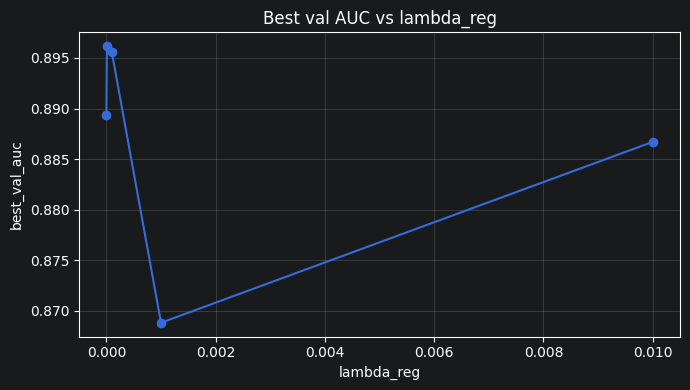

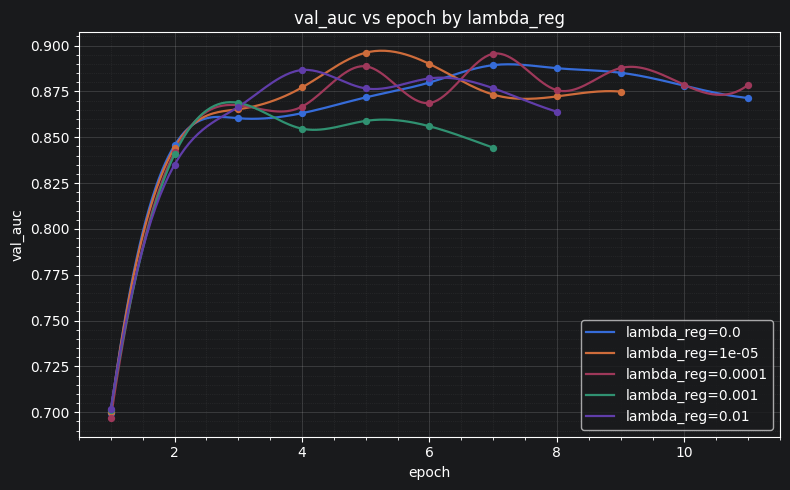


[EXPERIMENT START] impl=loss_regularization | n_settings=5 | exp_tag=20260805-182302/seed_53

[SETTING 1/5] tag=lam0e+00 | xai=False | settings=reg_mode=per_sample, lambda_reg=0, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam0e+00 | run_id=20260805-182302/seed_53__lam0e+00__e20 | xai=False | epochs=20 | seed=53
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 150s - 2s/step - auc: 0.7031 - loss: 0.6472 - val_auc: 0.7361 - val_loss: 0.6807 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 241ms/step - auc: 0.8847 - loss: 0.4646 - val_auc: 0.8611 - val_loss: 0.4462 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 229ms/step - auc: 0.9648 - loss: 0.2865 - val_auc: 0.8887 - val_loss: 0.4506 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 232ms/step - auc: 0.9876 - loss: 0.1844 - val_auc: 0.9160 - val_loss: 0.4469 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 14s - 208ms/step - auc: 0.9977 - loss: 0.1168 - val_auc: 0.9057 - val_loss: 0.5665 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 14s - 209ms/step - auc: 0.9989 - loss: 0.0953 - val_auc: 0.8981 - val_loss: 0.6407 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 14s - 209ms/step - auc: 0.9997 - loss: 0.0835 - val_auc: 0.8944 - val_loss: 0.6264 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 210ms/step - auc: 0.9998 - loss: 0.0791 - val_auc: 0.9017 - val_loss: 0.6538 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.6883 - loss: 0.6504 - val_auc: 0.7403 - val_loss: 0.6792 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 16s - 231ms/step - auc: 0.8842 - loss: 0.4657 - val_auc: 0.8553 - val_loss: 0.4652 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 230ms/step - auc: 0.9644 - loss: 0.2874 - val_auc: 0.8805 - val_loss: 0.4634 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 235ms/step - auc: 0.9897 - loss: 0.1754 - val_auc: 0.8839 - val_loss: 0.5381 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 234ms/step - auc: 0.9961 - loss: 0.1256 - val_auc: 0.8888 - val_loss: 0.5432 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 238ms/step - auc: 0.9991 - loss: 0.0964 - val_auc: 0.8967 - val_loss: 0.6404 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 221ms/step - auc: 0.9996 - loss: 0.0828 - val_auc: 0.8868 - val_loss: 0.6362 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 220ms/step - auc: 0.9998 - loss: 0.0770 - val_auc: 0.8961 - val_loss: 0.7074 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (3 outputs left out)

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.6986 - loss: 0.6473 - val_auc: 0.7372 - val_loss: 0.6848 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 45s - 645ms/step - auc: 0.8824 - loss: 0.4661 - val_auc: 0.8553 - val_loss: 0.4630 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 252ms/step - auc: 0.9655 - loss: 0.2829 - val_auc: 0.8994 - val_loss: 0.4456 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 17s - 249ms/step - auc: 0.9881 - loss: 0.1834 - val_auc: 0.9021 - val_loss: 0.5058 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 17s - 241ms/step - auc: 0.9978 - loss: 0.1143 - val_auc: 0.9060 - val_loss: 0.5898 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 234ms/step - auc: 0.9992 - loss: 0.0970 - val_auc: 0.9141 - val_loss: 0.5269 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 14s - 209ms/step - auc: 0.9998 - loss: 0.0826 - val_auc: 0.9017 - val_loss: 0.5746 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 211ms/step - auc: 0.9996 - loss: 0.0776 - val_auc: 0.8949 - val_loss: 0.5479 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.6956 - loss: 0.6477 - val_auc: 0.7391 - val_loss: 0.6806 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 19s - 271ms/step - auc: 0.8834 - loss: 0.4661 - val_auc: 0.8559 - val_loss: 0.4584 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 237ms/step - auc: 0.9625 - loss: 0.2914 - val_auc: 0.8968 - val_loss: 0.4341 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 14s - 209ms/step - auc: 0.9900 - loss: 0.1742 - val_auc: 0.8831 - val_loss: 0.5551 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 234ms/step - auc: 0.9963 - loss: 0.1270 - val_auc: 0.9036 - val_loss: 0.5232 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 15s - 211ms/step - auc: 0.9986 - loss: 0.0997 - val_auc: 0.8987 - val_loss: 0.5809 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 14s - 210ms/step - auc: 0.9994 - loss: 0.0874 - val_auc: 0.8780 - val_loss: 0.6726 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 213ms/step - auc: 0.9998 - loss: 0.0758 - val_auc: 0.8811 - val_loss: 0.6034 -

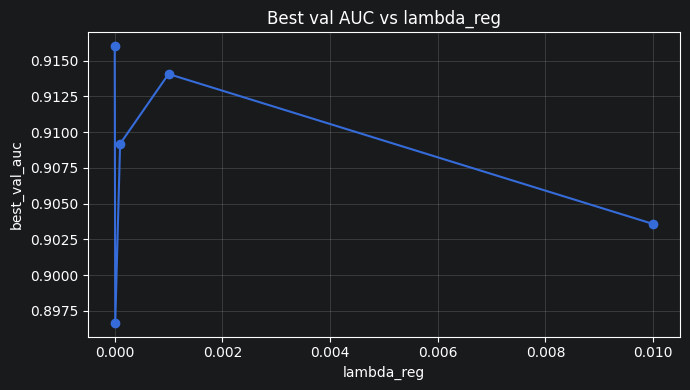

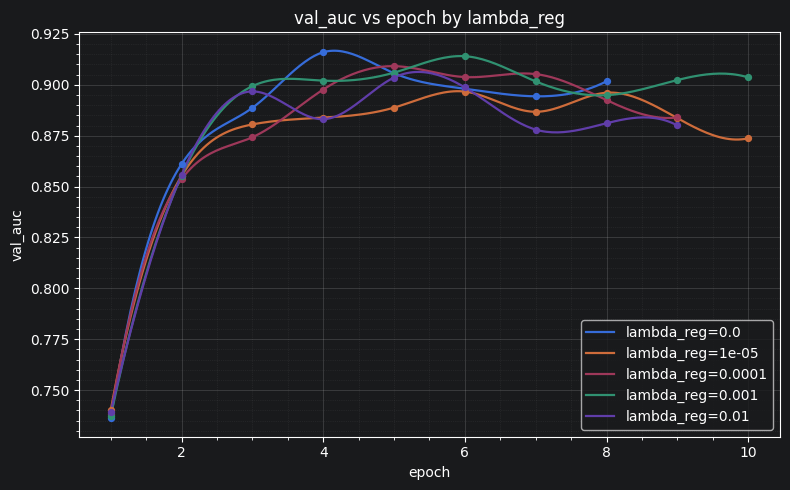


[EXPERIMENT START] impl=loss_regularization | n_settings=5 | exp_tag=20260805-182302/seed_71

[SETTING 1/5] tag=lam0e+00 | xai=False | settings=reg_mode=per_sample, lambda_reg=0, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam0e+00 | run_id=20260805-182302/seed_71__lam0e+00__e20 | xai=False | epochs=20 | seed=71
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.5939 - loss: 0.6794 - val_auc: 0.6046 - val_loss: 0.6676 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 16s - 238ms/step - auc: 0.8813 - loss: 0.4718 - val_auc: 0.8457 - val_loss: 0.4712 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 233ms/step - auc: 0.9599 - loss: 0.2924 - val_auc: 0.8961 - val_loss: 0.4302 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 14s - 208ms/step - auc: 0.9878 - loss: 0.1816 - val_auc: 0.8960 - val_loss: 0.4897 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 14s - 210ms/step - auc: 0.9960 - loss: 0.1282 - val_auc: 0.8865 - val_loss: 0.5778 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 15s - 211ms/step - auc: 0.9981 - loss: 0.1051 - val_auc: 0.8773 - val_loss: 0.5879 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 14s - 209ms/step - auc: 0.9993 - loss: 0.0897 - val_auc: 0.8900 - val_loss: 0.5828 - learning_rate: 3.0300e-04
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 3.
--------------------

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 150s - 2s/step - auc: 0.6047 - loss: 0.6766 - val_auc: 0.6035 - val_loss: 0.6684 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 239ms/step - auc: 0.8829 - loss: 0.4703 - val_auc: 0.8576 - val_loss: 0.4673 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 232ms/step - auc: 0.9611 - loss: 0.2886 - val_auc: 0.8763 - val_loss: 0.4502 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 233ms/step - auc: 0.9888 - loss: 0.1780 - val_auc: 0.8786 - val_loss: 0.5114 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 233ms/step - auc: 0.9958 - loss: 0.1297 - val_auc: 0.8818 - val_loss: 0.5736 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 232ms/step - auc: 0.9983 - loss: 0.1047 - val_auc: 0.8915 - val_loss: 0.6132 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 213ms/step - auc: 0.9991 - loss: 0.0891 - val_auc: 0.8855 - val_loss: 0.6182 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 211ms/step - auc: 0.9996 - loss: 0.0839 - val_auc: 0.8653 - val_loss: 0.6495 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.6017 - loss: 0.6780 - val_auc: 0.6058 - val_loss: 0.6689 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 16s - 236ms/step - auc: 0.8819 - loss: 0.4698 - val_auc: 0.8453 - val_loss: 0.4769 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 231ms/step - auc: 0.9600 - loss: 0.2938 - val_auc: 0.8838 - val_loss: 0.4500 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 14s - 210ms/step - auc: 0.9871 - loss: 0.1860 - val_auc: 0.8705 - val_loss: 0.5575 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 232ms/step - auc: 0.9966 - loss: 0.1248 - val_auc: 0.8858 - val_loss: 0.5691 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 15s - 211ms/step - auc: 0.9987 - loss: 0.1012 - val_auc: 0.8763 - val_loss: 0.6739 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 210ms/step - auc: 0.9992 - loss: 0.0907 - val_auc: 0.8527 - val_loss: 0.7160 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 211ms/step - auc: 0.9999 - loss: 0.0775 - val_auc: 0.8693 - val_loss: 0.6857 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 152s - 2s/step - auc: 0.6047 - loss: 0.6778 - val_auc: 0.6034 - val_loss: 0.6678 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 16s - 233ms/step - auc: 0.8811 - loss: 0.4732 - val_auc: 0.8490 - val_loss: 0.4777 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 232ms/step - auc: 0.9607 - loss: 0.2894 - val_auc: 0.8769 - val_loss: 0.4656 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 235ms/step - auc: 0.9873 - loss: 0.1828 - val_auc: 0.8798 - val_loss: 0.5308 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 15s - 212ms/step - auc: 0.9954 - loss: 0.1292 - val_auc: 0.8748 - val_loss: 0.6294 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 15s - 211ms/step - auc: 0.9984 - loss: 0.0984 - val_auc: 0.8634 - val_loss: 0.6625 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 212ms/step - auc: 0.9992 - loss: 0.0883 - val_auc: 0.8608 - val_loss: 0.7307 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 212ms/step - auc: 0.9996 - loss: 0.0805 - val_auc: 0.8594 - val_loss: 0.6995 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 147s - 2s/step - auc: 0.6114 - loss: 0.6762 - val_auc: 0.6042 - val_loss: 0.6649 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 244ms/step - auc: 0.8819 - loss: 0.4704 - val_auc: 0.8452 - val_loss: 0.4710 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 233ms/step - auc: 0.9614 - loss: 0.2897 - val_auc: 0.8843 - val_loss: 0.4382 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 233ms/step - auc: 0.9878 - loss: 0.1823 - val_auc: 0.8966 - val_loss: 0.4515 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 15s - 212ms/step - auc: 0.9954 - loss: 0.1342 - val_auc: 0.8962 - val_loss: 0.5178 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 236ms/step - auc: 0.9982 - loss: 0.1033 - val_auc: 0.8971 - val_loss: 0.5631 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 16s - 235ms/step - auc: 0.9994 - loss: 0.0870 - val_auc: 0.9080 - val_loss: 0.5784 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 213ms/step - auc: 0.9996 - loss: 0.0810 - val_auc: 0.8871 - val_loss: 0.6071 -

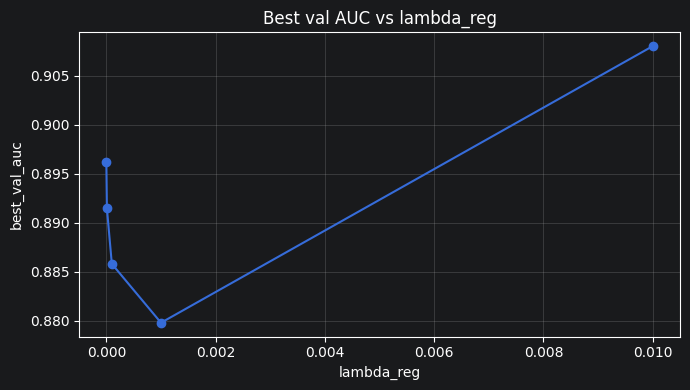

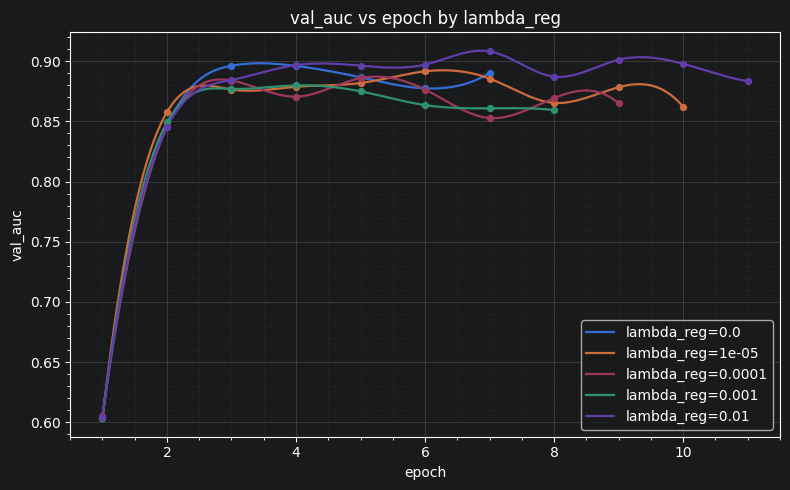


[EXPERIMENT START] impl=loss_regularization | n_settings=5 | exp_tag=20260805-182302/seed_8

[SETTING 1/5] tag=lam0e+00 | xai=False | settings=reg_mode=per_sample, lambda_reg=0, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam0e+00 | run_id=20260805-182302/seed_8__lam0e+00__e20 | xai=False | epochs=20 | seed=8
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 152s - 2s/step - auc: 0.7259 - loss: 0.6437 - val_auc: 0.7347 - val_loss: 0.6395 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 240ms/step - auc: 0.8932 - loss: 0.4559 - val_auc: 0.8497 - val_loss: 0.4718 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 16s - 239ms/step - auc: 0.9630 - loss: 0.2867 - val_auc: 0.8667 - val_loss: 0.4605 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 19s - 272ms/step - auc: 0.9884 - loss: 0.1792 - val_auc: 0.8843 - val_loss: 0.5402 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 17s - 244ms/step - auc: 0.9973 - loss: 0.1201 - val_auc: 0.8848 - val_loss: 0.5843 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 232ms/step - auc: 0.9988 - loss: 0.0971 - val_auc: 0.8947 - val_loss: 0.5923 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 16s - 234ms/step - auc: 0.9994 - loss: 0.0894 - val_auc: 0.8956 - val_loss: 0.6199 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 213ms/step - auc: 0.9996 - loss: 0.0811 - val_auc: 0.8767 - val_loss: 0.6030 -

2026-08-05 19:51:17.747516: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


--------------------------------------------------------------------------------------------------------------
[RUN END]| best_epoch=6 | best_val_auc=0.895587 | xai_done=False | time=311.8s

[SETTING 2/5] tag=lam1e-05 | xai=False | settings=reg_mode=per_sample, lambda_reg=1e-05, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam1e-05 | run_id=20260805-182302/seed_8__lam1e-05__e20 | xai=False | epochs=20 | seed=8
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (3 outputs left out)

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 151s - 2s/step - auc: 0.7210 - loss: 0.6452 - val_auc: 0.7384 - val_loss: 0.6398 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 245ms/step - auc: 0.8930 - loss: 0.4589 - val_auc: 0.8484 - val_loss: 0.4685 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 248ms/step - auc: 0.9634 - loss: 0.2863 - val_auc: 0.8659 - val_loss: 0.4632 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 236ms/step - auc: 0.9894 - loss: 0.1775 - val_auc: 0.8881 - val_loss: 0.5415 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 237ms/step - auc: 0.9962 - loss: 0.1257 - val_auc: 0.9016 - val_loss: 0.5446 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 14s - 210ms/step - auc: 0.9988 - loss: 0.0989 - val_auc: 0.8829 - val_loss: 0.6277 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 211ms/step - auc: 0.9996 - loss: 0.0850 - val_auc: 0.8748 - val_loss: 0.6679 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 210ms/step - auc: 0.9996 - loss: 0.0778 - val_auc: 0.8898 - val_loss: 0.5895 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 148s - 2s/step - auc: 0.7179 - loss: 0.6447 - val_auc: 0.7368 - val_loss: 0.6404 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 16s - 237ms/step - auc: 0.8899 - loss: 0.4613 - val_auc: 0.8507 - val_loss: 0.4706 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 242ms/step - auc: 0.9644 - loss: 0.2835 - val_auc: 0.8551 - val_loss: 0.4824 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 17s - 242ms/step - auc: 0.9873 - loss: 0.1854 - val_auc: 0.8722 - val_loss: 0.5120 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 19s - 273ms/step - auc: 0.9963 - loss: 0.1229 - val_auc: 0.8878 - val_loss: 0.5748 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 239ms/step - auc: 0.9989 - loss: 0.0952 - val_auc: 0.8920 - val_loss: 0.6196 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 211ms/step - auc: 0.9991 - loss: 0.0918 - val_auc: 0.8682 - val_loss: 0.6719 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 220ms/step - auc: 0.9999 - loss: 0.0773 - val_auc: 0.8694 - val_loss: 0.6875 -

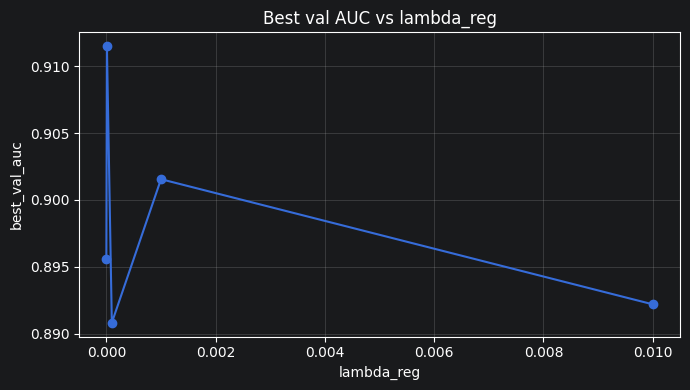

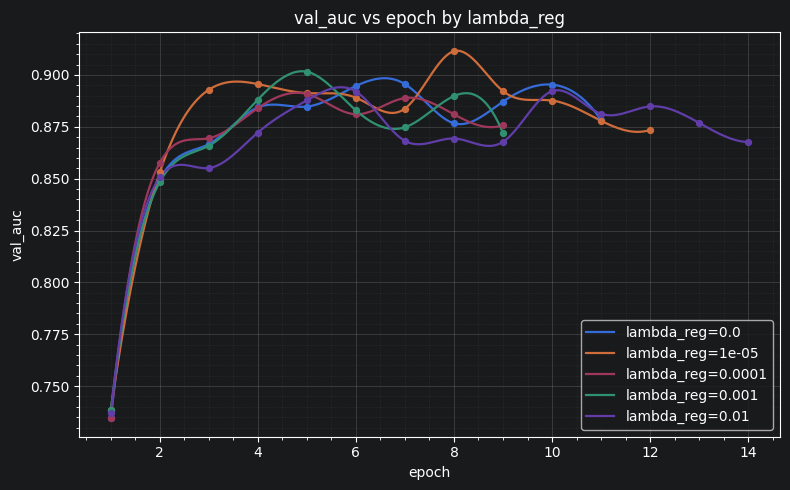


[EXPERIMENT START] impl=loss_regularization | n_settings=5 | exp_tag=20260805-182302/seed_90

[SETTING 1/5] tag=lam0e+00 | xai=False | settings=reg_mode=per_sample, lambda_reg=0, penalty_on=tabular
[RUN START] impl=loss_regularization | tag=lam0e+00 | run_id=20260805-182302/seed_90__lam0e+00__e20 | xai=False | epochs=20 | seed=90
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 148s - 2s/step - auc: 0.6998 - loss: 0.6446 - val_auc: 0.6908 - val_loss: 0.6681 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 243ms/step - auc: 0.8754 - loss: 0.4767 - val_auc: 0.8251 - val_loss: 0.4845 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 242ms/step - auc: 0.9593 - loss: 0.2971 - val_auc: 0.8648 - val_loss: 0.4993 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 17s - 240ms/step - auc: 0.9875 - loss: 0.1852 - val_auc: 0.8545 - val_loss: 0.5979 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 17s - 249ms/step - auc: 0.9966 - loss: 0.1224 - val_auc: 0.8801 - val_loss: 0.6239 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 236ms/step - auc: 0.9983 - loss: 0.1024 - val_auc: 0.8929 - val_loss: 0.6937 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 211ms/step - auc: 0.9995 - loss: 0.0870 - val_auc: 0.8830 - val_loss: 0.7270 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 15s - 213ms/step - auc: 0.9995 - loss: 0.0821 - val_auc: 0.8660 - val_loss: 0.7498 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 - 137s - 2s/step - auc: 0.6970 - loss: 0.6455 - val_auc: 0.6912 - val_loss: 0.6619 - learning_rate: 2.5000e-05
Epoch 2/20
69/69 - 17s - 247ms/step - auc: 0.8718 - loss: 0.4818 - val_auc: 0.8329 - val_loss: 0.4811 - learning_rate: 1.2333e-04
Epoch 3/20
69/69 - 17s - 239ms/step - auc: 0.9595 - loss: 0.2958 - val_auc: 0.8445 - val_loss: 0.5089 - learning_rate: 2.2167e-04
Epoch 4/20
69/69 - 16s - 233ms/step - auc: 0.9876 - loss: 0.1843 - val_auc: 0.8734 - val_loss: 0.5847 - learning_rate: 3.2000e-04
Epoch 5/20
69/69 - 16s - 234ms/step - auc: 0.9958 - loss: 0.1295 - val_auc: 0.8751 - val_loss: 0.5767 - learning_rate: 3.1808e-04
Epoch 6/20
69/69 - 16s - 237ms/step - auc: 0.9992 - loss: 0.0940 - val_auc: 0.8879 - val_loss: 0.6617 - learning_rate: 3.1236e-04
Epoch 7/20
69/69 - 15s - 212ms/step - auc: 0.9993 - loss: 0.0906 - val_auc: 0.8846 - val_loss: 0.6422 - learning_rate: 3.0300e-04
Epoch 8/20
69/69 - 16s - 234ms/step - auc: 0.9996 - loss: 0.0821 - val_auc: 0.8896 - val_loss: 0.6165 -

/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (19 outputs left out)

2026-08-05 20:45:25.688648: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50364416 bytes after encountering the first element of size 50364416 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2026-08-05 20:45:25.688972: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50364928 bytes after encountering the first element of size 50364928 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


69/69 - 15s - 221ms/step - auc: 0.9998 - loss: 0.0751 - val_auc: 0.8864 - val_loss: 0.6662 - learning_rate: 2.7431e-04
Epoch 10/20


2026-08-05 20:45:40.987113: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50364416 bytes after encountering the first element of size 50364416 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2026-08-05 20:45:40.993357: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50364928 bytes after encountering the first element of size 50364928 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


69/69 - 15s - 219ms/step - auc: 0.9999 - loss: 0.0728 - val_auc: 0.8775 - val_loss: 0.6456 - learning_rate: 2.5569e-04
Epoch 10: early stopping
Restoring model weights from the end of the best epoch: 6.
--------------------------------------------------------------------------------------------------------------
[RUN END]| best_epoch=5 | best_val_auc=0.886501 | xai_done=False | time=276.7s

[EXPERIMENT END] impl=loss_regularization | completed_settings=5


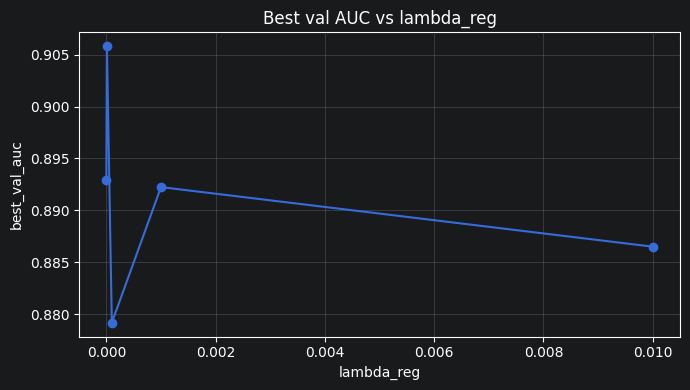

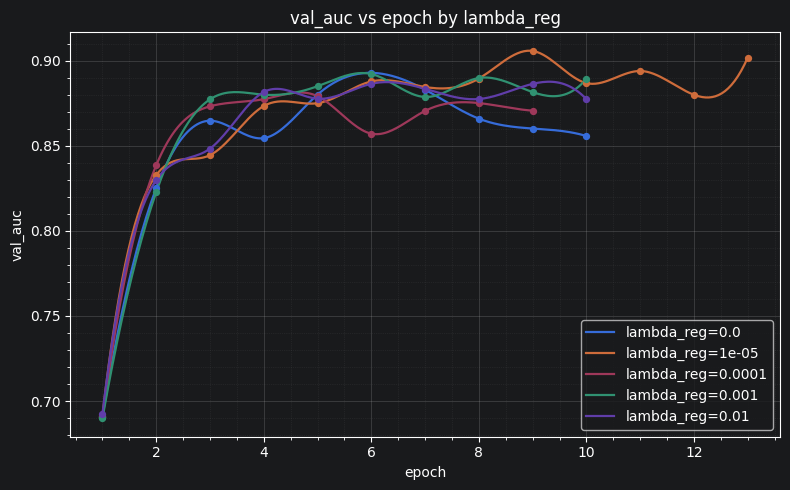

,lambda_reg,mean,std,count
0,0.00000,0.898011,0.010417,5
1,0.00001,0.900320,0.008123,5
2,0.00010,0.892111,0.011319,5
3,0.00100,0.891292,0.017766,5
4,0.01000,0.895403,0.009892,5


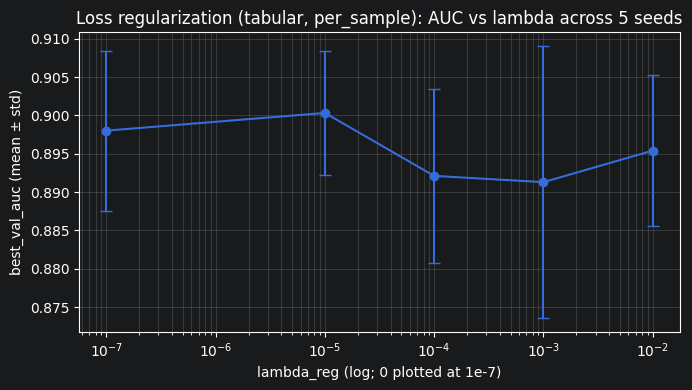

[study dir]: /mnt/disk1/home/cgiovannoni/isic24-dum/artifacts/enhanced/runs/loss_regularization/20260805-182302


In [32]:
# @@RETRAIN_LOSSREG@@ 3/3 — the sweep: 5 lambda x 5 seeds into a new canonical timestamp
assert "build_loss_regularized" in globals(), "run @@RETRAIN_LOSSREG@@ 1/3 (the builder) first"
assert "_probe" in globals(), "run @@RETRAIN_LOSSREG@@ 2/3 (the pre-flight) first"
REG_MODE = "per_sample"   # per_batch would silently disable class_weight
PENALTY_ON = "tabular"
LAMBDA_REGS = [0, 1e-5, 1e-4, 1e-3, 1e-2]
XAI_LAMBDAS = LAMBDA_REGS
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

REG_SETTINGS = [
    {"tag": f"lam{l:.0e}", "lambda_reg": float(l)}
    for l in LAMBDA_REGS
]

study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "loss_regularization", study_tag)
os.makedirs(study_dir, exist_ok=True)

all_results = []
all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    reg_results, reg_histories, reg_summary_dir = run_model_experiment(
        impl_name="loss_regularization",
        settings=REG_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: build_loss_regularized(
            lambda_reg=s["lambda_reg"],
            penalty_on=PENALTY_ON,
            reg_mode=REG_MODE,
            run_eagerly=run_eagerly,
        ),
        enable_xai_fn=lambda s: float(s["lambda_reg"]) in XAI_LAMBDAS,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {
            "reg_mode": REG_MODE,
            "lambda_reg": float(s["lambda_reg"]),
            "penalty_on": PENALTY_ON,
        },
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(reg_results)
    all_histories.update({f"{seed}__{k}": v for k, v in reg_histories.items()})

    # per-seed plots inside seed folder
    seed_plots_dir = os.path.join(reg_summary_dir, "plots")
    plot_param_vs_best_auc(reg_results, "lambda_reg", out_dir=seed_plots_dir)
    plot_lore_xai_suite(reg_results, "lambda_reg", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        reg_results, reg_histories, setting_col="lambda_reg",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_lambda_reg_sweep.png",
    )

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg = combined.groupby("lambda_reg")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg.to_csv(os.path.join(study_dir, "lambda_reg_aggregated.csv"), index=False)
display(agg)

# Plot mean ± std across seeds (log-x because lambda spans orders of magnitude)
fig, ax = plt.subplots(figsize=(7, 4))
# Replace lambda_reg=0 with a small floor for log scale display only
x_plot = agg["lambda_reg"].replace(0, 1e-7)
ax.errorbar(x_plot, agg["mean"], yerr=agg["std"], marker="o", capsize=4)
ax.set_xscale("log")
ax.set_xlabel("lambda_reg (log; 0 plotted at 1e-7)")
ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Loss regularization ({PENALTY_ON}, {REG_MODE}): "
             f"AUC vs lambda across {len(SEEDS)} seeds")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)
plt.savefig(os.path.join(study_plots, "lambda_reg_vs_auc_mean_std.png"), dpi=300)
plt.show()
plt.close()

print("[study dir]:", study_dir)

### Controlled fusion (post‑training weighting)  
This variant replaces the standard merge with a weighted sum of the two modality embeddings:  
`fused = gamma_img * z_img + gamma_tab * z_tab`.  
It lets you manually bias the model toward image or tabular features *after training* by changing `gamma_img` and `gamma_tab` (both non‑trainable).  
Note: `z_img` and `z_tab` must have the same dimensionality, since they are summed.

The narrative is "constrain the easier modality to force the model to use vision. Image-penalty isn't motivated; "both" is redundant with L2 weight decay. Document the decision.

In [ ]:
# Controlled fusion — model builder (FusionWithGamma imported from isic24.mod_attendance).
def build_gamma_fusion(setting, run_eagerly=False):
    gamma_img = float(setting.get("gamma_img", 1.0))
    gamma_tab = float(setting.get("gamma_tab", 1.0))

    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)
    x1 = keras.layers.Dense(128, activation="linear", name="img_proj")(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)

    fused = FusionWithGamma(gamma_img=gamma_img, gamma_tab=gamma_tab, name="fusion_with_gamma")([x1, x2])
    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(fused)

    model = keras.Model(inp, out, name="controlled_fusion")
    opt = keras.optimizers.Adam.from_config(adam.get_config())
    model.compile(
        optimizer=opt,
        loss=bce,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model

In [ ]:
# Controlled fusion — multi-seed
CF_TAG = "base"
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

CONTROLLED_FUSION_SETTINGS = [
    {"tag": CF_TAG, "gamma_img": 1.0, "gamma_tab": 1.0}
]

# Single macro folder for entire multi-seed study
study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "controlled_fusion", study_tag)
os.makedirs(study_dir, exist_ok=True)

cf_all_results = []
cf_all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    cf_seed_results, cf_seed_histories, cf_summary_dir = run_model_experiment(
        impl_name="controlled_fusion",
        settings=CONTROLLED_FUSION_SETTINGS,
        build_model_from_setting_fn=build_gamma_fusion,
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {
            "gamma_img": float(s["gamma_img"]),
            "gamma_tab": float(s["gamma_tab"]),
        },
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    cf_all_results.append(cf_seed_results)
    cf_all_histories.update({f"{seed}__{k}": v for k, v in cf_seed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(cf_summary_dir, "plots")
    plot_lore_xai_suite(cf_seed_results, "gamma_img", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        cf_seed_results, cf_seed_histories, setting_col="gamma_img",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_controlled_fusion.png",
    )

# Cross-seed aggregation
cf_combined = pd.concat(cf_all_results, ignore_index=True)
cf_combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

cf_agg = (
    cf_combined.groupby(["setting_tag", "gamma_img", "gamma_tab"], dropna=False)["best_val_auc"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
cf_agg.to_csv(os.path.join(study_dir, "controlled_fusion_aggregated.csv"), index=False)
display(cf_combined[["impl_name", "run_id", "setting_tag", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])
display(cf_agg)
print(f"AUC: {cf_combined['best_val_auc'].mean():.4f} ± {cf_combined['best_val_auc'].std():.4f}")
print("[study dir]:", study_dir)

In [ ]:
# Per-run training curves (loss & val_auc), saved to each run's plots/ folder
for _, row in cf_combined.iterrows():
    cf_run_dir = row["run_dir"]
    with open(os.path.join(cf_run_dir, "history.json")) as f:
        cf_hist = json.load(f)

    plots_dir = os.path.join(cf_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    if "val_auc" in cf_hist and len(cf_hist["val_auc"]) > 0:
        x = np.arange(1, len(cf_hist["val_auc"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, cf_hist["val_auc"], marker="o")
        plt.xlabel("epoch"); plt.ylabel("val_auc")
        plt.title("Controlled fusion: val_auc vs epoch")
        plt.grid(alpha=0.3)
        _finalize_plot(plots_dir, "val_auc_vs_epoch.png")

    if "loss" in cf_hist and "val_loss" in cf_hist and len(cf_hist["loss"]) > 0:
        x = np.arange(1, len(cf_hist["loss"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, cf_hist["loss"], marker="o", label="loss")
        plt.plot(x, cf_hist["val_loss"], marker="o", label="val_loss")
        plt.xlabel("epoch"); plt.ylabel("loss")
        plt.title("Controlled fusion: loss vs epoch")
        plt.grid(alpha=0.3)
        plt.legend()
        _finalize_plot(plots_dir, "loss_vs_epoch.png")

 After training, you can manually adjust them to bias the final prediction toward one modality without retraining

### Adaptive gating

In [ ]:
# Adaptive gating — model builder (GateEntropyLoss imported from isic24.mod_attendance).
def build_adaptive_gating(setting, run_eagerly=False):
    entropy_weight = float(setting.get("entropy_weight", 1e-4))

    image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
    feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
    inp = {"images": image_input, "features": feat_input}

    backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
    x1 = backbone(image_input)
    x1 = keras.layers.GlobalAveragePooling2D()(x1)
    x1 = keras.layers.Dropout(0.2)(x1)
    x1 = keras.layers.Dense(256, activation="selu", name="img_emb")(x1)

    x2 = keras.layers.Dense(96, activation="selu")(feat_input)
    x2 = keras.layers.Dense(128, activation="selu")(x2)
    x2 = keras.layers.Dropout(0.1)(x2)
    x2 = keras.layers.Dense(256, activation="selu", name="tab_emb")(x2)

    fusion_input = keras.layers.Concatenate(name="fusion_input")([x1, x2])
    gate = keras.layers.Dense(64, activation="relu")(fusion_input)
    gate = keras.layers.Dense(2, activation="softmax", name="gate_weights")(gate)
    gate = GateEntropyLoss(weight=entropy_weight, name="gate_entropy_loss")(gate)

    w_img = keras.layers.Lambda(lambda w: w[:, 0:1], name="w_img")(gate)
    w_tab = keras.layers.Lambda(lambda w: w[:, 1:2], name="w_tab")(gate)

    x1_w = keras.layers.Multiply(name="weighted_img")([x1, w_img])
    x2_w = keras.layers.Multiply(name="weighted_tab")([x2, w_tab])
    fused = keras.layers.Add(name="fused")([x1_w, x2_w])

    out = keras.layers.Dense(1, activation="sigmoid", dtype="float32", name="output")(fused)

    model = keras.Model(inp, out, name="adaptive_gating")
    opt = keras.optimizers.Adam.from_config(adam.get_config())
    model.compile(
        optimizer=opt,
        loss=bce,
        metrics=[keras.metrics.AUC(name="auc")],
        run_eagerly=run_eagerly,
        jit_compile=not run_eagerly,
    )
    return model


In [ ]:
# Adaptive gating — multi-seed
AG_SETTING = {"tag": "base", "entropy_weight": 1e-4}
EPOCHS = CFG.epochs
SEEDS = [47, 53, 71, 8, 90]

ADAPTIVE_GATING_SETTINGS = [AG_SETTING]

# Single macro folder for entire multi-seed study
study_tag = _make_exp_tag()
study_dir = os.path.join(RUNS_PATH, "adaptive_gating", study_tag)
os.makedirs(study_dir, exist_ok=True)

ag_all_results = []
ag_all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    ag_seed_results, ag_seed_histories, ag_summary_dir = run_model_experiment(
        impl_name="adaptive_gating",
        settings=ADAPTIVE_GATING_SETTINGS,
        build_model_from_setting_fn=build_adaptive_gating,
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"entropy_weight": float(s["entropy_weight"])},
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    ag_all_results.append(ag_seed_results)
    ag_all_histories.update({f"{seed}__{k}": v for k, v in ag_seed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(ag_summary_dir, "plots")
    plot_lore_xai_suite(ag_seed_results, "entropy_weight", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        ag_seed_results, ag_seed_histories, setting_col="entropy_weight",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_adaptive_gating.png",
    )

# Cross-seed aggregation
ag_combined = pd.concat(ag_all_results, ignore_index=True)
ag_combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

ag_agg = ag_combined.groupby("entropy_weight")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
ag_agg.to_csv(os.path.join(study_dir, "entropy_weight_aggregated.csv"), index=False)
display(ag_combined[["impl_name", "run_id", "setting_tag", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])
display(ag_agg)
print(f"AUC: {ag_combined['best_val_auc'].mean():.4f} ± {ag_combined['best_val_auc'].std():.4f}")
print("[study dir]:", study_dir)


In [ ]:
for _, row in ag_combined.iterrows():
    ag_run_dir = row["run_dir"]
    with open(os.path.join(ag_run_dir, "history.json")) as f:
        ag_hist = json.load(f)

    plots_dir = os.path.join(ag_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    if "val_auc" in ag_hist and len(ag_hist["val_auc"]) > 0:
        x = np.arange(1, len(ag_hist["val_auc"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, ag_hist["val_auc"], marker="o")
        plt.xlabel("epoch"); plt.ylabel("val_auc")
        plt.title("Adaptive gating: val_auc vs epoch")
        plt.grid(alpha=0.3)
        _finalize_plot(plots_dir, "val_auc_vs_epoch.png")

    if "loss" in ag_hist and "val_loss" in ag_hist and len(ag_hist["loss"]) > 0:
        x = np.arange(1, len(ag_hist["loss"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, ag_hist["loss"], marker="o", label="loss")
        plt.plot(x, ag_hist["val_loss"], marker="o", label="val_loss")
        plt.xlabel("epoch"); plt.ylabel("loss")
        plt.title("Adaptive gating: loss vs epoch")
        plt.grid(alpha=0.3)
        plt.legend()
        _finalize_plot(plots_dir, "loss_vs_epoch.png")